<a href="https://colab.research.google.com/github/anderafryanto-dotcom/Spirulina-based-Microcapsules-Control-Release/blob/main/Note_3_Feed_Delivery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ==========================================================
# NOTEBOOK 3
# RELEASE MODEL COMPARISON
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

import os
import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from sklearn.model_selection import (
    GroupKFold,
    learning_curve
)

# ----------------------------------------------------------
# LINEAR REGRESSION MODELS
# ----------------------------------------------------------
from sklearn.linear_model import (
    Ridge
)

from sklearn.cross_decomposition import PLSRegression

# ----------------------------------------------------------
# NON-LINEAR REGRESSION MODELS
# ----------------------------------------------------------
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor
)

from xgboost import XGBRegressor

# ----------------------------------------------------------
# MODEL CATEGORIES
# ----------------------------------------------------------
LINEAR_MODELS = [
    "Ridge",
    "PLSR"
]

NONLINEAR_MODELS = [
    "Random Forest",
    "Extra Trees",
    "XGBoost"
]

ALL_MODELS = LINEAR_MODELS + NONLINEAR_MODELS

print("Linear models:", LINEAR_MODELS)
print("Non-linear models:", NONLINEAR_MODELS)
print("Total models:", len(ALL_MODELS))


Linear models: ['Ridge', 'PLSR']
Non-linear models: ['Random Forest', 'Extra Trees', 'XGBoost']
Total models: 5


In [ ]:
# ==========================================================
# LOAD RELEASE DATASET
# ==========================================================

X_train = joblib.load(
    "X_train_release.pkl"
)

X_test = joblib.load(
    "X_test_release.pkl"
)

y_train = joblib.load(
    "y_train_release.pkl"
)

y_test = joblib.load(
    "y_test_release.pkl"
)

train_groups = joblib.load(
    "train_groups.pkl"
)

test_groups = joblib.load(
    "test_groups.pkl"
)

print("X Train :", X_train.shape)
print("X Test  :", X_test.shape)

print("y Train :", y_train.shape)
print("y Test  :", y_test.shape)

print("Train Groups :", train_groups.nunique())
print("Test Groups  :", test_groups.nunique())

X Train : (120, 606)
X Test  : (30, 606)
y Train : (120,)
y Test  : (30,)
Train Groups : 24
Test Groups  : 6


In [ ]:
# ==========================================================
# CHECK GROUP LEAKAGE
# ==========================================================

overlap = set(
    train_groups
).intersection(
    set(test_groups)
)

print(
    "Number of overlapping groups :",
    len(overlap)
)

Number of overlapping groups : 0


In [ ]:

# ==========================================================
# DEFINE 5 MODELS
# ==========================================================

models = {

    # ------------------------------------------------------
    # LINEAR MODELS
    # ------------------------------------------------------

    "Ridge":
    Ridge(
        random_state=42
    ),

    "PLSR":
    PLSRegression(
        n_components=10
    ),

    # ------------------------------------------------------
    # NON-LINEAR MODELS
    # ------------------------------------------------------

    "Random Forest":
    RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees":
    ExtraTreesRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost":
    XGBRegressor(
        objective="reg:squarederror",
        n_estimators=300,
        random_state=42,
        verbosity=0,
        n_jobs=-1
    )

}

# ----------------------------------------------------------
# MODEL SUMMARY
# ----------------------------------------------------------

LINEAR_MODELS = [
    "Ridge",
    "PLSR"
]

NONLINEAR_MODELS = [
    "Random Forest",
    "Extra Trees",
    "XGBoost"
]

print("Total models :", len(models))
print("Linear models:", len(LINEAR_MODELS))
print("Non-linear models:", len(NONLINEAR_MODELS))

for name in models:
    print("-", name)


Total models : 5
Linear models: 2
Non-linear models: 3
- Ridge
- PLSR
- Random Forest
- Extra Trees
- XGBoost


In [ ]:
# ==========================================================
# SAFE MAPE
# ==========================================================

def safe_mape(y_true, y_pred):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mask = y_true != 0

    if mask.sum() == 0:
        return np.nan

    return np.mean(
        np.abs(
            (
                y_true[mask]
                -
                y_pred[mask]
            )
            /
            y_true[mask]
        )
    ) * 100

In [ ]:
# ==========================================================
# EVALUATION FUNCTION
# ==========================================================

def evaluate_model(
    y_true,
    y_pred
):

    r2 = r2_score(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    mape = safe_mape(
        y_true,
        y_pred
    )

    return {

        "R2": r2,

        "RMSE": rmse,

        "MAE": mae,

        "MAPE": mape

    }

In [ ]:
# ==========================================================
# PREDICTED VS EXPERIMENTAL
# ==========================================================

def plot_prediction(
    y_true,
    y_pred,
    model_name,
    dataset_name
):

    plt.figure(
        figsize=(6,6)
    )

    plt.scatter(
        y_true,
        y_pred,
        alpha=0.75,
        s=50
    )

    min_val = min(
        np.min(y_true),
        np.min(y_pred)
    )

    max_val = max(
        np.max(y_true),
        np.max(y_pred)
    )

    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        "--",
        linewidth=2
    )

    plt.xlabel(
        "Experimental Release"
    )

    plt.ylabel(
        "Predicted Release"
    )

    plt.title(
        f"{model_name} - {dataset_name}"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()

In [ ]:
# ==========================================================
# RESIDUAL PLOT
# ==========================================================

def plot_residual(
    y_true,
    y_pred,
    model_name
):

    residual = (
        np.asarray(y_true)
        -
        np.asarray(y_pred)
    )

    plt.figure(
        figsize=(6,5)
    )

    plt.scatter(
        y_pred,
        residual,
        alpha=0.75,
        s=50
    )

    plt.axhline(
        0,
        linestyle="--",
        linewidth=2
    )

    plt.xlabel(
        "Predicted Release"
    )

    plt.ylabel(
        "Residual"
    )

    plt.title(
        f"{model_name} - Residual Plot"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()

In [ ]:
# ==========================================================
# RESIDUAL DISTRIBUTION
# ==========================================================

def plot_residual_distribution(
    y_true,
    y_pred,
    model_name
):

    residual = (
        np.asarray(y_true)
        -
        np.asarray(y_pred)
    )

    plt.figure(
        figsize=(6,5)
    )

    sns.histplot(
        residual,
        kde=True
    )

    plt.axvline(
        0,
        linestyle="--",
        linewidth=2
    )

    plt.xlabel(
        "Residual"
    )

    plt.ylabel(
        "Frequency"
    )

    plt.title(
        f"{model_name} - Residual Distribution"
    )

    plt.tight_layout()

    plt.show()

In [ ]:
# ==========================================================
# LEARNING CURVE
# ==========================================================

def plot_learning_curve(
    model,
    X,
    y,
    groups,
    model_name
):

    cv = GroupKFold(
        n_splits=5
    )

    train_sizes, train_scores, validation_scores = learning_curve(

        model,

        X,

        y,

        groups=groups,

        cv=cv,

        scoring="r2",

        train_sizes=np.linspace(
            0.2,
            1.0,
            5
        ),

        n_jobs=-1

    )

    train_mean = train_scores.mean(
        axis=1
    )

    validation_mean = validation_scores.mean(
        axis=1
    )

    plt.figure(
        figsize=(7,5)
    )

    plt.plot(
        train_sizes,
        train_mean,
        marker="o",
        linewidth=2,
        label="Training"
    )

    plt.plot(
        train_sizes,
        validation_mean,
        marker="s",
        linewidth=2,
        label="Validation"
    )

    plt.xlabel(
        "Number of Training Samples"
    )

    plt.ylabel(
        "R²"
    )

    plt.title(
        f"{model_name} - Learning Curve"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()

In [ ]:
# ==========================================================
# CREATE OUTPUT FOLDERS
# ==========================================================

os.makedirs(
    "Release_Predictions",
    exist_ok=True
)

os.makedirs(
    "Release_Models",
    exist_ok=True
)

In [ ]:
import numpy as np
# ==========================================================
# TRAIN ALL 5 MODELS
# ==========================================================

results = []

trained_models = {}

predictions = {}

# Drop non-numeric columns that are not features
X_train_processed = X_train.drop(columns=['Sample_ID'])
X_test_processed = X_test.drop(columns=['Sample_ID'])

for model_name, model in models.items():

    print("\n")
    print("=" * 80)
    print("MODEL :", model_name)
    print("=" * 80)

    # ------------------------------------------------------
    # TRAIN
    # ------------------------------------------------------

    model.fit(
        X_train_processed,
        y_train
    )

    trained_models[
        model_name
    ] = model


    # ------------------------------------------------------
    # PREDICTION
    # ------------------------------------------------------

    pred_train = model.predict(
        X_train_processed
    )

    pred_test = model.predict(
        X_test_processed
    )


    predictions[
        model_name
    ] = {

        "train": pred_train,

        "test": pred_test

    }


    # ------------------------------------------------------
    # EVALUATION
    # ------------------------------------------------------

    train_metric = evaluate_model(
        y_train,
        pred_train
    )

    test_metric = evaluate_model(
        y_test,
        pred_test
    )


    # ------------------------------------------------------
    # STORE RESULT
    # ------------------------------------------------------

    results.append({

        "Model":
        model_name,

        "Train_R2":
        train_metric["R2"],

        "Train_RMSE":
        train_metric["RMSE"],

        "Train_MAE":
        train_metric["MAE"],

        "Train_MAPE":
        train_metric["MAPE"],

        "Test_R2":
        test_metric["R2"],

        "Test_RMSE":
        test_metric["RMSE"],

        "Test_MAE":
        test_metric["MAE"],

        "Test_MAPE":
        test_metric["MAPE"]

    })


    # ------------------------------------------------------
    # PRINT RESULT
    # ------------------------------------------------------

    print(
        "Train R² :",
        round(train_metric["R2"],4)
    )

    print(
        "Test R²  :",
        round(test_metric["R2"],4)
    )

    print(
        "Test RMSE :",
        round(test_metric["RMSE"],4)
    )

    print(
        "Test MAE :",
        round(test_metric["MAE"],4)
    )

    print(
        "Test MAPE :",
        round(test_metric["MAPE"],4)
    )




MODEL : Ridge
Train R² : 0.8054
Test R²  : 0.8777
Test RMSE : 0.0002
Test MAE : 0.0001
Test MAPE : 47.8996


MODEL : PLSR
Train R² : 0.9928
Test R²  : 0.9527
Test RMSE : 0.0001
Test MAE : 0.0001
Test MAPE : 52.2274


MODEL : Random Forest
Train R² : 0.9803
Test R²  : 0.9699
Test RMSE : 0.0001
Test MAE : 0.0001
Test MAPE : 40.4801


MODEL : Extra Trees
Train R² : 1.0
Test R²  : 0.94
Test RMSE : 0.0001
Test MAE : 0.0001
Test MAPE : 35.316


MODEL : XGBoost
Train R² : 0.9542
Test R²  : 0.8964
Test RMSE : 0.0002
Test MAE : 0.0002
Test MAPE : 46.4669



Learning Curve: Ridge


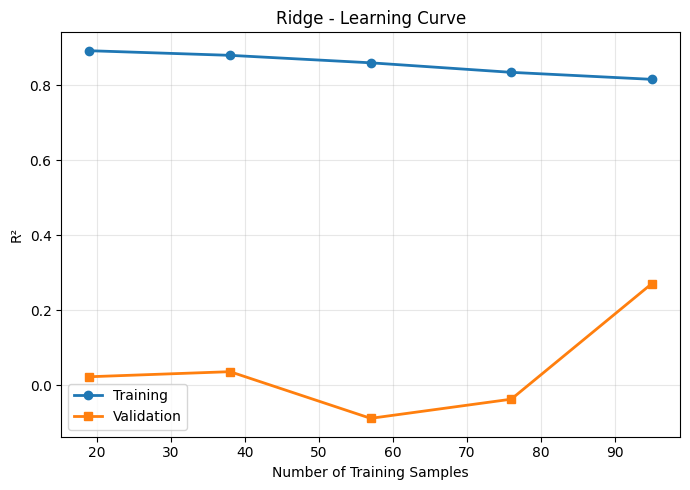


Learning Curve: PLSR


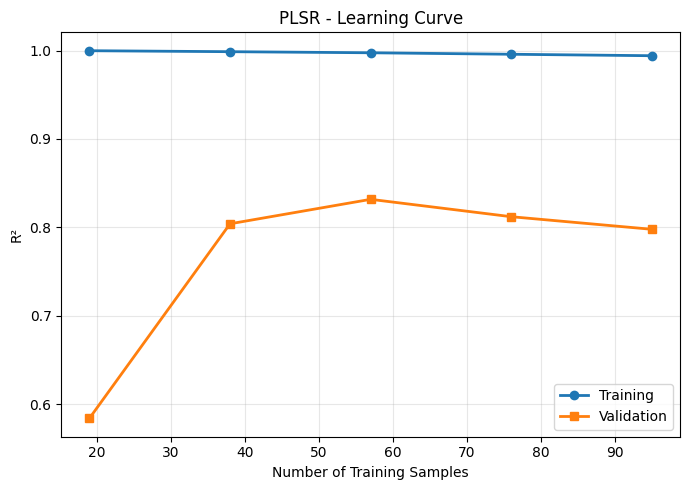


Learning Curve: Random Forest


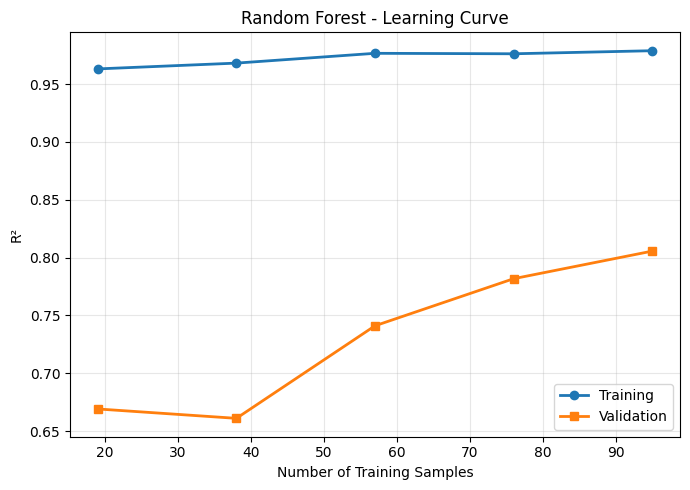


Learning Curve: Extra Trees


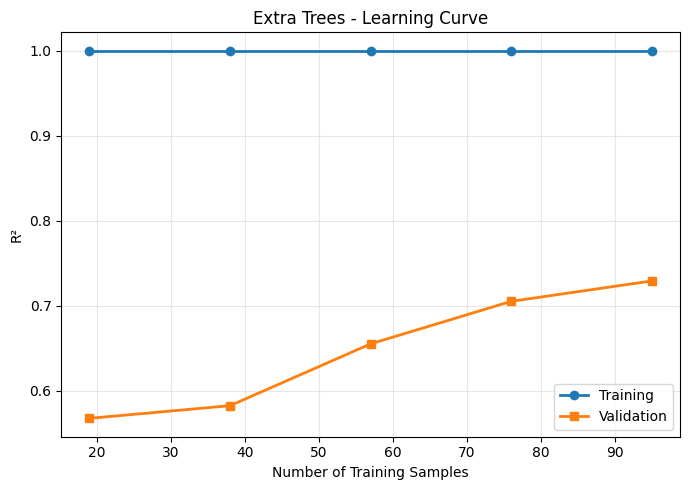


Learning Curve: XGBoost


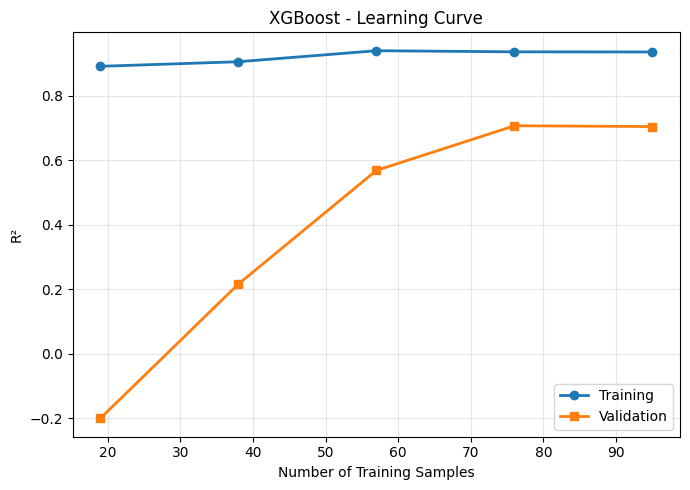

In [ ]:
# ==========================================================
# LEARNING CURVES
# ==========================================================

for model_name, model in trained_models.items():

    print(
        "\nLearning Curve:",
        model_name
    )

    plot_learning_curve(

        model,

        X_train_processed,

        y_train,

        train_groups,

        model_name

    )


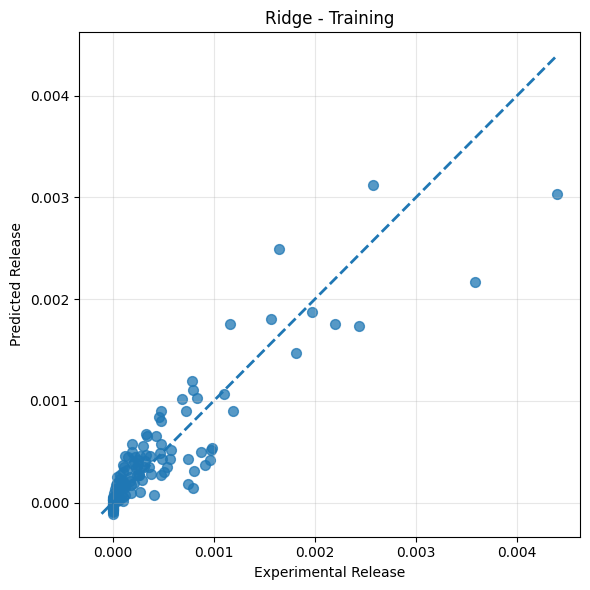

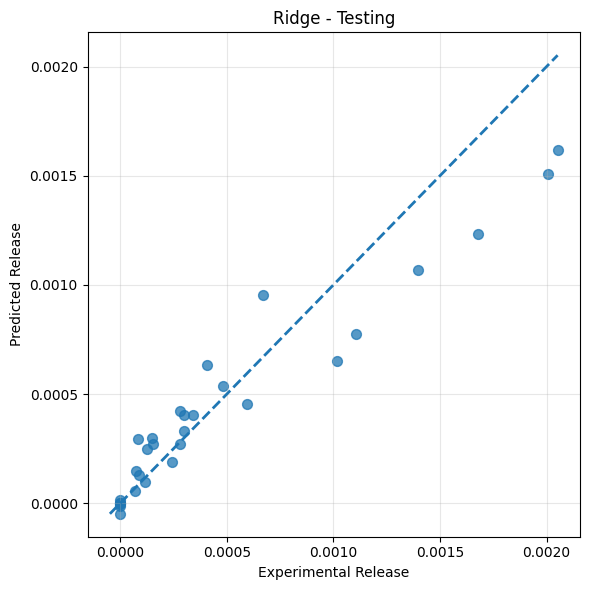

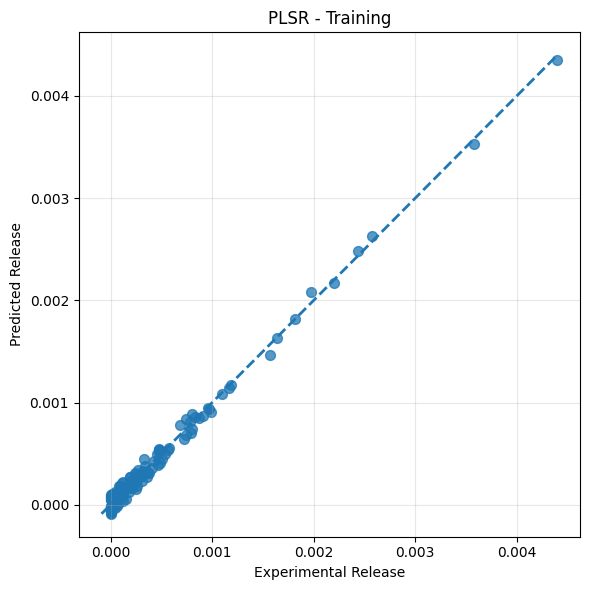

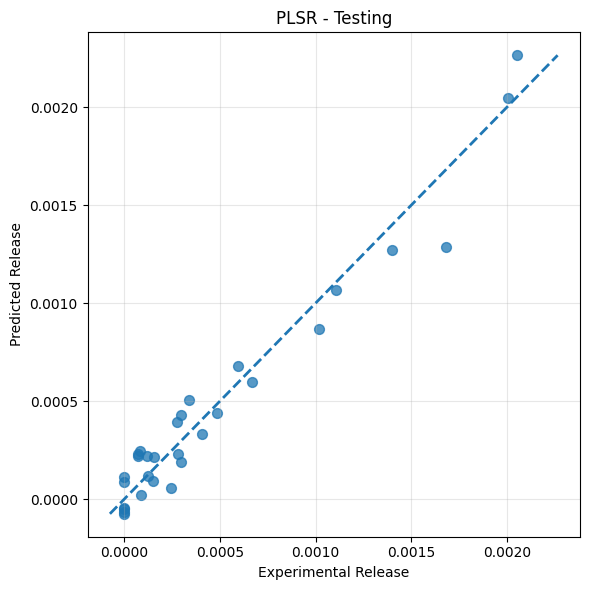

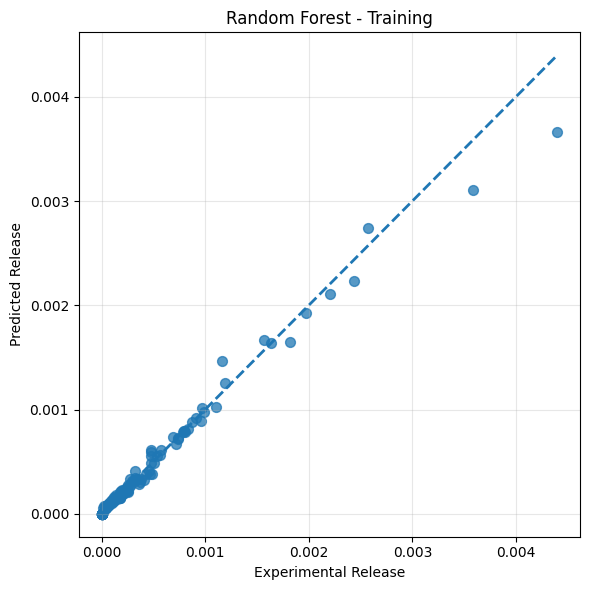

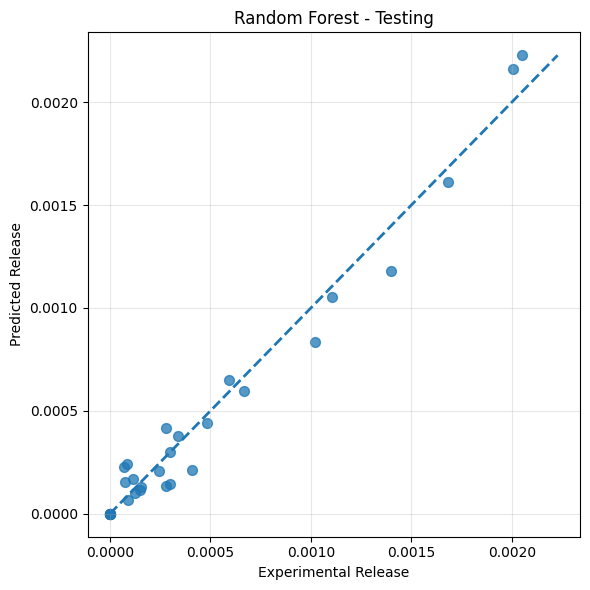

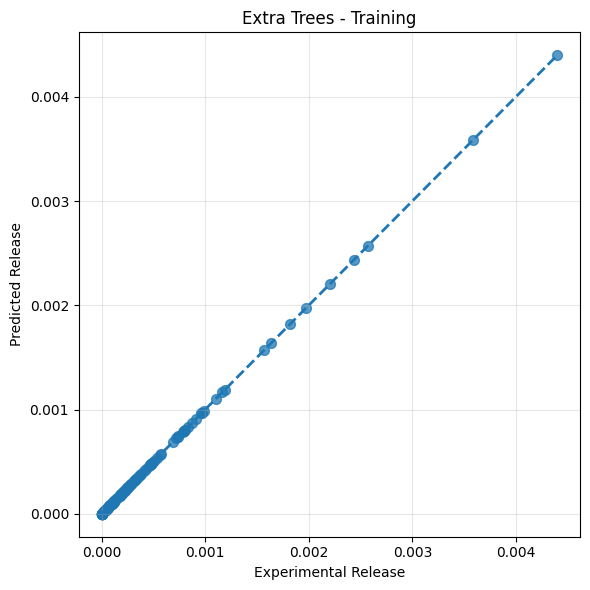

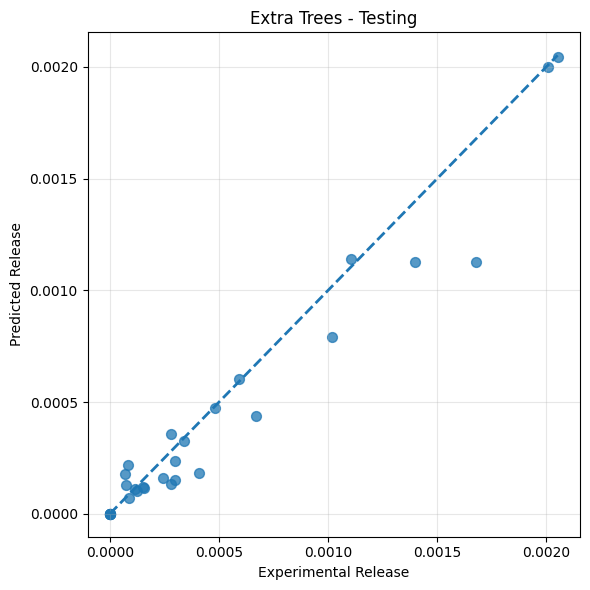

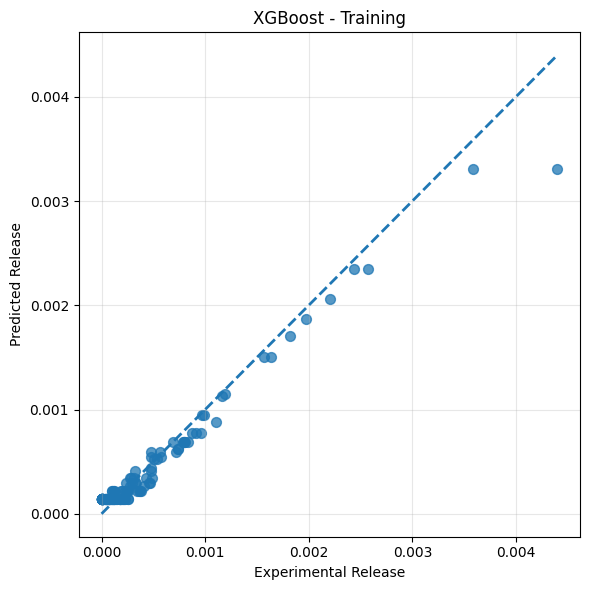

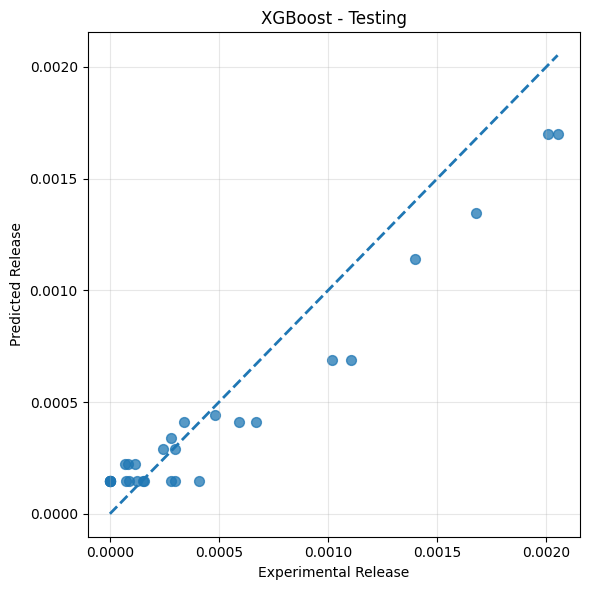

In [ ]:
# ==========================================================
# PREDICTED VS EXPERIMENTAL
# ==========================================================

for model_name in trained_models.keys():

    pred_train = predictions[
        model_name
    ]["train"]

    pred_test = predictions[
        model_name
    ]["test"]


    # TRAIN

    plot_prediction(

        y_train,

        pred_train,

        model_name,

        "Training"

    )


    # TEST

    plot_prediction(

        y_test,

        pred_test,

        model_name,

        "Testing"

    )

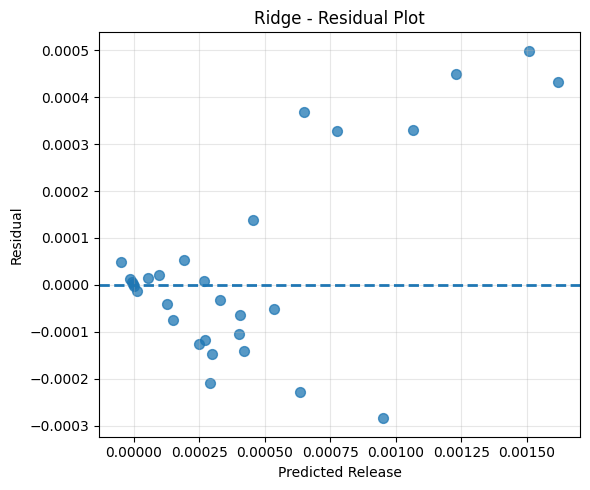

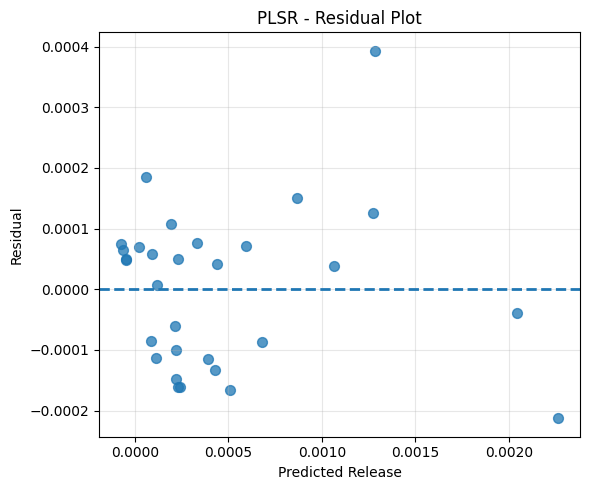

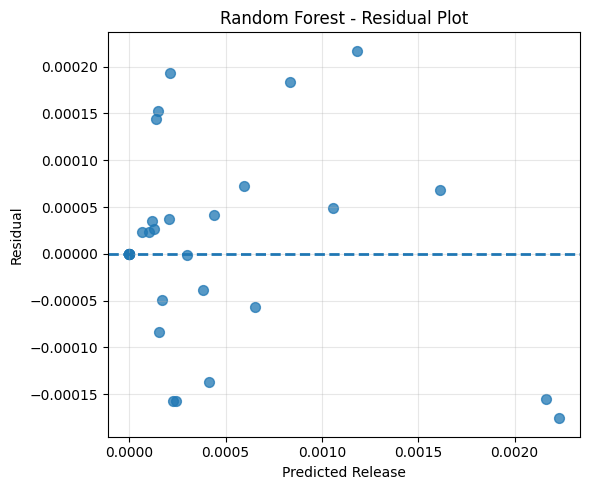

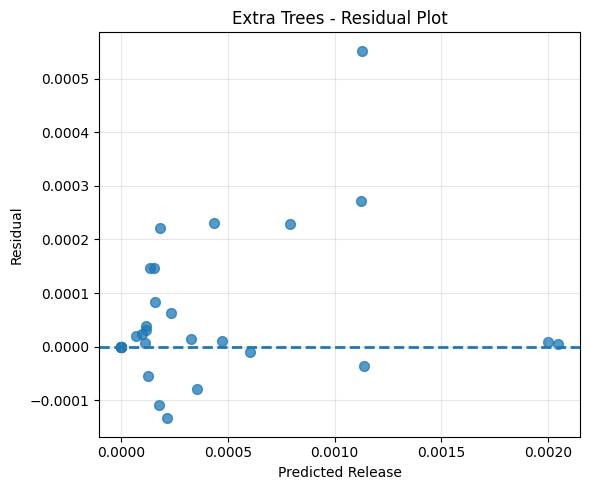

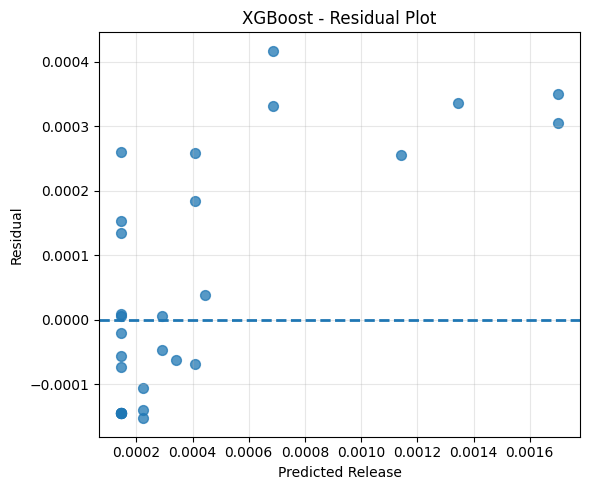

In [ ]:
# ==========================================================
# RESIDUAL PLOTS
# ==========================================================

for model_name in trained_models.keys():

    pred_test = predictions[
        model_name
    ]["test"]

    plot_residual(

        y_test,

        pred_test,

        model_name

    )

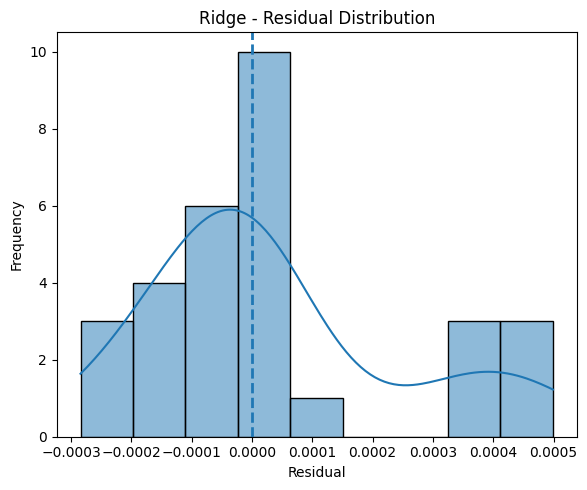

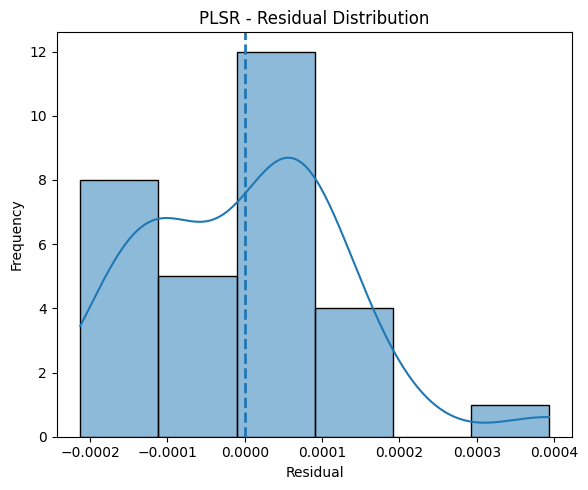

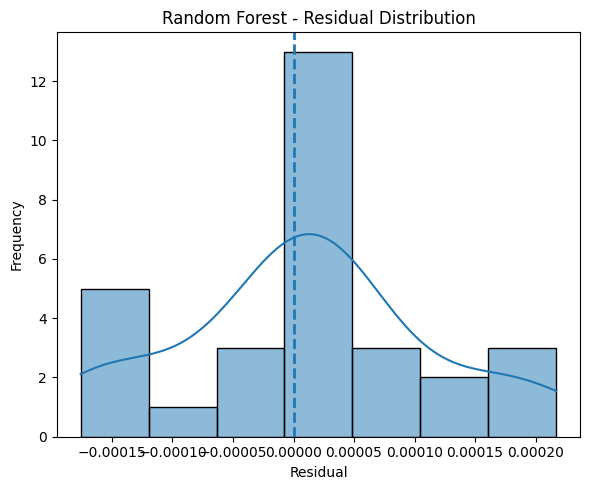

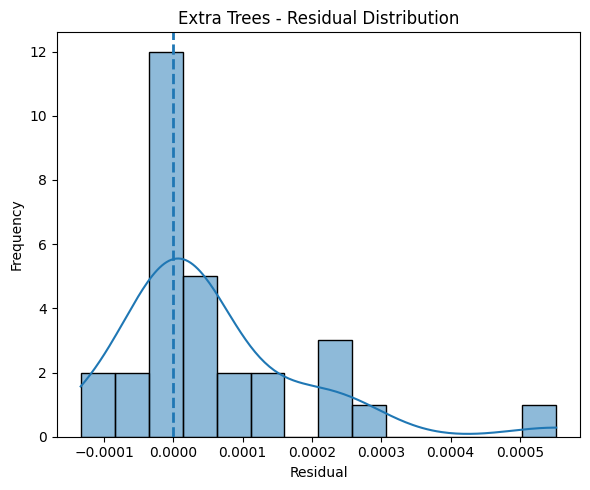

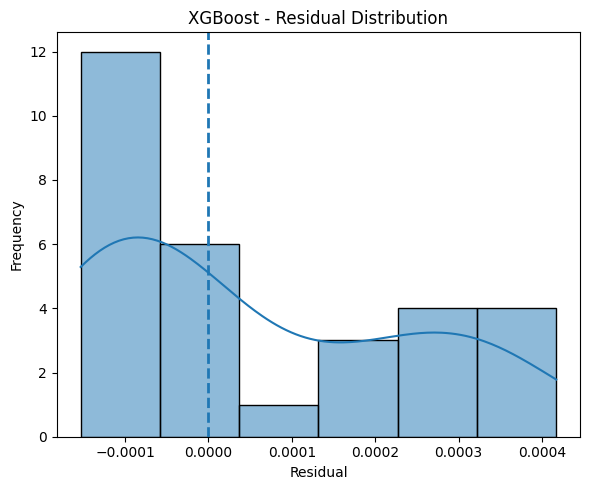

In [ ]:
# ==========================================================
# RESIDUAL DISTRIBUTION
# ==========================================================

for model_name in trained_models.keys():

    pred_test = predictions[
        model_name
    ]["test"]

    plot_residual_distribution(

        y_test,

        pred_test,

        model_name

    )

In [ ]:
# ==========================================================
# MODEL COMPARISON
# ==========================================================

result_df = pd.DataFrame(
    results
)

result_df = result_df.sort_values(

    "Test_R2",

    ascending=False

)

display(
    result_df
)

,Model,Train_R2,Train_RMSE,Train_MAE,Train_MAPE,Test_R2,Test_RMSE,Test_MAE,Test_MAPE
2,Random Forest,0.980286,9.701755e-05,4.139494e-05,1.916150e+01,0.969854,0.000103,0.000076,40.480106
1,PLSR,0.992762,5.878507e-05,5.068136e-05,3.463738e+01,0.952711,0.000129,0.000106,52.227449
3,Extra Trees,1.000000,2.974542e-18,1.546852e-18,3.665677e-13,0.940045,0.000145,0.000084,35.315976
4,XGBoost,0.954198,1.478785e-04,1.030256e-04,5.656830e+01,0.896352,0.000191,0.000155,46.466861
0,Ridge,0.805357,3.048470e-04,1.980153e-04,8.628818e+01,0.877703,0.000207,0.000145,47.899582


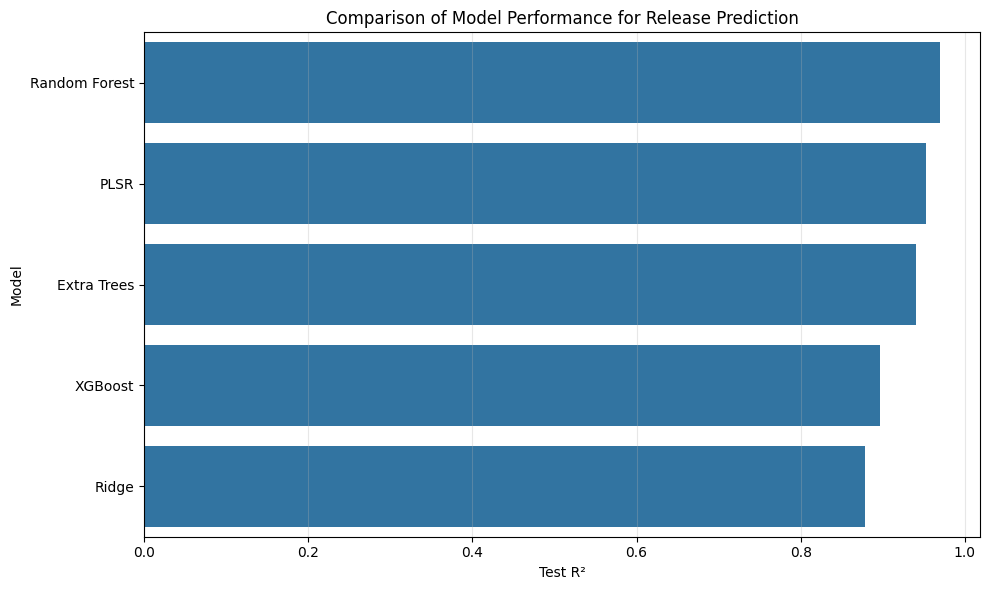

In [ ]:
# ==========================================================
# MODEL TEST R² COMPARISON
# ==========================================================

plt.figure(
    figsize=(10,6)
)

sns.barplot(

    data=result_df,

    x="Test_R2",

    y="Model"

)

plt.xlabel(
    "Test R²"
)

plt.ylabel(
    "Model"
)

plt.title(
    "Comparison of Model Performance for Release Prediction"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# SAVE MODEL COMPARISON
# ==========================================================

result_df.to_excel(

    "Release_Model_Comparison.xlsx",

    index=False

)

result_df.to_csv(

    "Release_Model_Comparison.csv",

    index=False
)

In [ ]:
# ==========================================================
# SAVE ALL TRAINED MODELS
# ==========================================================

joblib.dump(

    trained_models,

    "Release_All_Models.pkl"

)

['Release_All_Models.pkl']

In [ ]:
# ==========================================================
# SAVE PREDICTIONS
# ==========================================================

for model_name in predictions.keys():

    pred_train = predictions[
        model_name
    ]["train"]

    pred_test = predictions[
        model_name
    ]["test"]


    prediction_df = pd.DataFrame({

        "Experimental_Train":
        np.asarray(y_train),

        "Predicted_Train":
        np.asarray(pred_train),

    })


    prediction_test_df = pd.DataFrame({

        "Experimental_Test":
        np.asarray(y_test),

        "Predicted_Test":
        np.asarray(pred_test),

    })


    safe_name = (
        model_name
        .replace(" ","_")
    )


    prediction_df.to_excel(

        f"Release_Predictions/"
        f"{safe_name}_Train.xlsx",

        index=False

    )


    prediction_test_df.to_excel(

        f"Release_Predictions/"
        f"{safe_name}_Test.xlsx",

        index=False

    )

In [ ]:
# ==========================================================
# BEST BASELINE MODEL
# ==========================================================

best_model_name = result_df.iloc[0]["Model"]

best_baseline_model = trained_models[
    best_model_name
]

print("=" * 80)

print(
    "BEST BASELINE MODEL FOR RELEASE:"
)

print(
    best_model_name
)

print()

print(
    "Test R²:",
    result_df.iloc[0]["Test_R2"]
)

print(
    "Test RMSE:",
    result_df.iloc[0]["Test_RMSE"]
)

print(
    "Test MAE:",
    result_df.iloc[0]["Test_MAE"]
)

BEST BASELINE MODEL FOR RELEASE:
Random Forest

Test R²: 0.969854231015249
Test RMSE: 0.00010287103711934049
Test MAE: 7.598816210905339e-05


In [ ]:
joblib.dump(

    best_model_name,

    "Release_Best_Baseline_Model_Name.pkl"

)

joblib.dump(

    best_baseline_model,

    "Release_Best_Baseline_Model.pkl"

)

['Release_Best_Baseline_Model.pkl']

In [ ]:
# ==========================================================
# PART 23
# PLSR HYPERPARAMETER OPTIMIZATION
# ==========================================================

from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import GroupKFold, cross_val_score

In [ ]:
# ==========================================================
# PLS COMPONENT RANGE
# ==========================================================

max_components = min(
    30,
    X_train.shape[1],
    X_train.shape[0] - 1
)

component_range = range(
    1,
    max_components + 1
)

print(
    "Testing components:",
    list(component_range)
)

Testing components: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]


In [ ]:
# ==========================================================
# GROUP K-FOLD
# ==========================================================

group_cv = GroupKFold(
    n_splits=5
)

In [ ]:
cv_results = []

for n_comp in component_range:

    pls = PLSRegression(
        n_components=n_comp
    )

    scores = cross_val_score(

        pls,

        X_train_processed,

        y_train,

        groups=train_groups,

        cv=group_cv,

        scoring="r2",

        n_jobs=-1

    )

    cv_results.append({

        "n_components": n_comp,

        "Mean_CV_R2": scores.mean(),

        "Std_CV_R2": scores.std()

    })

cv_results_df = pd.DataFrame(
    cv_results
)

display(
    cv_results_df
)

,n_components,Mean_CV_R2,Std_CV_R2
0,1,0.378074,0.526375
1,2,0.738588,0.214601
2,3,0.842477,0.151880
3,4,0.853785,0.104106
4,5,0.831570,0.149647
5,6,0.838350,0.160495
6,7,0.834719,0.149275
7,8,0.851408,0.119433
8,9,0.828721,0.157568
9,10,0.797678,0.190336


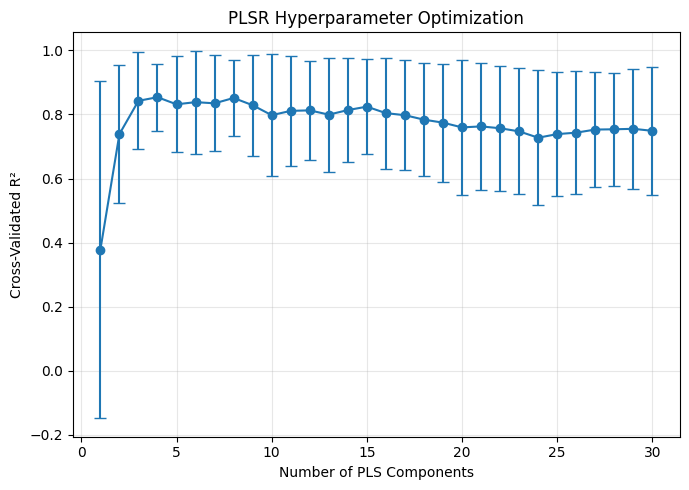

In [ ]:
# ==========================================================
# PLSR COMPONENT OPTIMIZATION PLOT
# ==========================================================

plt.figure(
    figsize=(7,5)
)

plt.errorbar(

    cv_results_df["n_components"],

    cv_results_df["Mean_CV_R2"],

    yerr=cv_results_df["Std_CV_R2"],

    marker="o",

    capsize=4

)

plt.xlabel(
    "Number of PLS Components"
)

plt.ylabel(
    "Cross-Validated R²"
)

plt.title(
    "PLSR Hyperparameter Optimization"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# BEST PLSR COMPONENT
# ==========================================================

best_components = cv_results_df.loc[
    cv_results_df["Mean_CV_R2"].idxmax(),
    "n_components"
]

best_cv_r2 = cv_results_df.loc[
    cv_results_df["Mean_CV_R2"].idxmax(),
    "Mean_CV_R2"
]

print(
    "Best number of PLS components:",
    int(best_components)
)

print(
    "Best CV R²:",
    best_cv_r2
)

Best number of PLS components: 4
Best CV R²: 0.8537851018989799


In [ ]:
# ==========================================================
# FINAL OPTIMIZED PLSR
# ==========================================================

final_plsr = PLSRegression(
    n_components=int(best_components)
)

final_plsr.fit(
    X_train_processed,
    y_train
)

PLSRegression(n_components=4)

In [ ]:
# ==========================================================
# FINAL PREDICTION
# ==========================================================

final_pred_train = final_plsr.predict(
    X_train_processed
).ravel()

final_pred_test = final_plsr.predict(
    X_test_processed
).ravel()

In [ ]:
# ==========================================================
# FINAL EVALUATION
# ==========================================================

final_train_metric = evaluate_model(
    y_train,
    final_pred_train
)

final_test_metric = evaluate_model(
    y_test,
    final_pred_test
)

print("="*70)

print("FINAL OPTIMIZED PLSR")
print()

print("Best Components :", int(best_components))

print()
print("TRAIN")
print(final_train_metric)

print()
print("TEST")
print(final_test_metric)

FINAL OPTIMIZED PLSR

Best Components : 4

TRAIN
{'R2': 0.9807040579997337, 'RMSE': np.float64(9.59831517883413e-05), 'MAE': 7.847557421004817e-05, 'MAPE': np.float64(46.21395152484513)}

TEST
{'R2': 0.9632025408922265, 'RMSE': np.float64(0.00011365507963990392), 'MAE': 9.67652809639533e-05, 'MAPE': np.float64(50.352049763667836)}


In [ ]:
# ==========================================================
# BASELINE VS OPTIMIZED
# ==========================================================

baseline_row = result_df[
    result_df["Model"] == "PLSR"
].iloc[0]

comparison = pd.DataFrame({

    "Model": [
        "Baseline PLSR",
        "Optimized PLSR"
    ],

    "Test_R2": [

        baseline_row["Test_R2"],

        final_test_metric["R2"]

    ],

    "Test_RMSE": [

        baseline_row["Test_RMSE"],

        final_test_metric["RMSE"]

    ],

    "Test_MAE": [

        baseline_row["Test_MAE"],

        final_test_metric["MAE"]

    ],

    "Test_MAPE": [

        baseline_row["Test_MAPE"],

        final_test_metric["MAPE"]

    ]

})

display(
    comparison
)

,Model,Test_R2,Test_RMSE,Test_MAE,Test_MAPE
0,Baseline PLSR,0.952711,0.000129,0.000106,52.227449
1,Optimized PLSR,0.963203,0.000114,0.000097,50.352050


In [ ]:
# ==========================================================
# SAVE PLSR OPTIMIZATION
# ==========================================================

cv_results_df.to_excel(
    "Release_PLSR_Component_Optimization.xlsx",
    index=False
)

comparison.to_excel(
    "Release_PLSR_Baseline_vs_Optimized.xlsx",
    index=False
)

In [ ]:
# ==========================================================
# SAVE FINAL PLSR MODEL
# ==========================================================

joblib.dump(
    final_plsr,
    "Release_Final_PLSR.pkl"
)

joblib.dump(
    int(best_components),
    "Release_Best_PLS_Components.pkl"
)

['Release_Best_PLS_Components.pkl']

In [ ]:
# ==========================================================
# PART 24
# RIDGE HYPERPARAMETER OPTIMIZATION
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, cross_val_score

# ==========================================================
# RIDGE ALPHA RANGE
# ==========================================================

alpha_range = np.logspace(-4, 4, 33)

print("Testing alpha values:")
print(alpha_range)

# ==========================================================
# GROUP K-FOLD
# ==========================================================

group_cv = GroupKFold(
    n_splits=5
)

cv_results = []

Testing alpha values:
[1.00000000e-04 1.77827941e-04 3.16227766e-04 5.62341325e-04
 1.00000000e-03 1.77827941e-03 3.16227766e-03 5.62341325e-03
 1.00000000e-02 1.77827941e-02 3.16227766e-02 5.62341325e-02
 1.00000000e-01 1.77827941e-01 3.16227766e-01 5.62341325e-01
 1.00000000e+00 1.77827941e+00 3.16227766e+00 5.62341325e+00
 1.00000000e+01 1.77827941e+01 3.16227766e+01 5.62341325e+01
 1.00000000e+02 1.77827941e+02 3.16227766e+02 5.62341325e+02
 1.00000000e+03 1.77827941e+03 3.16227766e+03 5.62341325e+03
 1.00000000e+04]


,alpha,Mean_CV_R2,Std_CV_R2
0,0.000100,0.714395,0.184466
1,0.000178,0.715113,0.183877
2,0.000316,0.716359,0.182856
3,0.000562,0.718483,0.181114
4,0.001000,0.721993,0.178231
5,0.001778,0.727506,0.173686
6,0.003162,0.735486,0.167018
7,0.005623,0.745731,0.158154
8,0.010000,0.756902,0.147718
9,0.017783,0.766849,0.137223


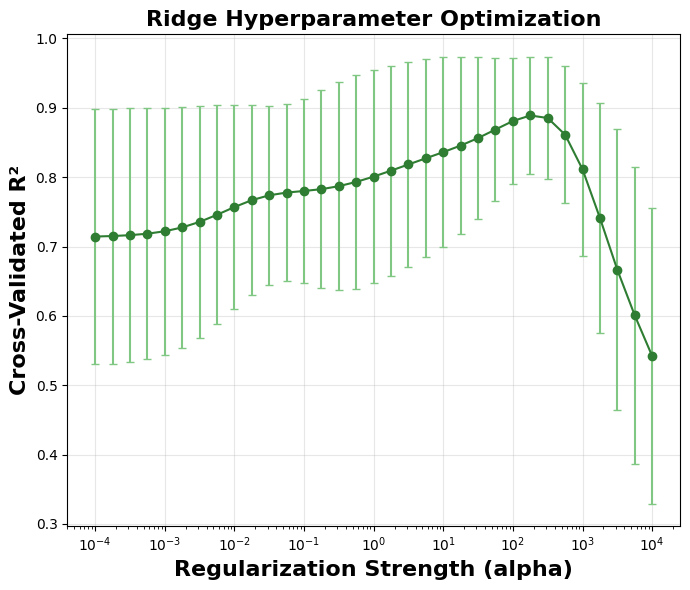

BEST RIDGE HYPERPARAMETERS
Best alpha : 177.82794100389228
Best CV R² : 0.8889612565042275
CV R² Std  : 0.08480572265196518


In [ ]:
# ==========================================================
# RIDGE HYPERPARAMETER SEARCH
# ==========================================================

for alpha in alpha_range:

    ridge_pipeline = Pipeline([

        ("scaler", StandardScaler()),

        ("ridge", Ridge(
            alpha=alpha
        ))

    ])

    scores = cross_val_score(

        ridge_pipeline,

        X_train_processed,

        np.asarray(y_train).ravel(),

        groups=train_groups,

        cv=group_cv,

        scoring="r2",

        n_jobs=-1

    )

    cv_results.append({

        "alpha": alpha,

        "Mean_CV_R2": scores.mean(),

        "Std_CV_R2": scores.std()

    })

cv_results_df = pd.DataFrame(
    cv_results
)

display(
    cv_results_df
)

# ==========================================================
# RIDGE OPTIMIZATION PLOT (Warna Hijau)
# ==========================================================

plt.figure(
    figsize=(7, 6)
)

plt.errorbar(

    cv_results_df["alpha"],

    cv_results_df["Mean_CV_R2"],

    yerr=cv_results_df["Std_CV_R2"],

    marker="o",

    capsize=3,

    color="#2e7d32",

    ecolor="#81c784",

    elinewidth=1.5

)

plt.xscale("log")

plt.xlabel(
    "Regularization Strength (alpha)", fontsize=16, fontweight='bold'
)

plt.ylabel(
    "Cross-Validated R²", fontsize=16, fontweight='bold'
)

plt.title(
    "Ridge Hyperparameter Optimization", fontsize=16, fontweight='bold'
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

# ==========================================================
# BEST RIDGE ALPHA
# ==========================================================

best_idx = cv_results_df["Mean_CV_R2"].idxmax()

best_alpha = cv_results_df.loc[
    best_idx,
    "alpha"
]

best_cv_r2 = cv_results_df.loc[
    best_idx,
    "Mean_CV_R2"
]

best_cv_std = cv_results_df.loc[
    best_idx,
    "Std_CV_R2"
]

print("=" * 70)
print("BEST RIDGE HYPERPARAMETERS")
print("=" * 70)

print("Best alpha :", best_alpha)
print("Best CV R² :", best_cv_r2)
print("CV R² Std  :", best_cv_std)

In [ ]:
# ==========================================================
# FINAL OPTIMIZED RIDGE MODEL
# ==========================================================

final_ridge = Pipeline([

    ("scaler", StandardScaler()),

    ("ridge", Ridge(
        alpha=best_alpha
    ))

])

final_ridge.fit(

    X_train_processed,

    np.asarray(y_train).ravel()

)

# ==========================================================
# FINAL PREDICTION
# ==========================================================

final_pred_train = final_ridge.predict(
    X_train_processed
).ravel()

final_pred_test = final_ridge.predict(
    X_test_processed
).ravel()

# ==========================================================
# FINAL EVALUATION
# ==========================================================

final_train_metric = evaluate_model(
    np.asarray(y_train).ravel(),
    final_pred_train
)

final_test_metric = evaluate_model(
    np.asarray(y_test).ravel(),
    final_pred_test
)

print("=" * 70)
print("FINAL OPTIMIZED RIDGE")
print("=" * 70)

print("\nBest Alpha:", best_alpha)

print("\nTRAIN")
print(final_train_metric)

print("\nTEST")
print(final_test_metric)

FINAL OPTIMIZED RIDGE

Best Alpha: 177.82794100389228

TRAIN
{'R2': 0.9871832771409718, 'RMSE': np.float64(7.822588963667831e-05), 'MAE': 6.520816239434736e-05, 'MAPE': np.float64(41.36858786885654)}

TEST
{'R2': 0.9765038210725808, 'RMSE': np.float64(9.081938471860087e-05), 'MAE': 7.57164826148862e-05, 'MAPE': np.float64(41.44700867455564)}


In [ ]:
# ==========================================================
# BASELINE VS OPTIMIZED RIDGE
# ==========================================================

baseline_row = result_df.loc[
    result_df["Model"] == "Ridge"
].iloc[0]

comparison = pd.DataFrame({

    "Model": [
        "Baseline Ridge",
        "Optimized Ridge"
    ],

    "Test_R2": [

        baseline_row["Test_R2"],

        final_test_metric["R2"]

    ],

    "Test_RMSE": [

        baseline_row["Test_RMSE"],

        final_test_metric["RMSE"]

    ],

    "Test_MAE": [

        baseline_row["Test_MAE"],

        final_test_metric["MAE"]

    ],

    "Test_MAPE": [

        baseline_row["Test_MAPE"],

        final_test_metric["MAPE"]

    ]

})

display(
    comparison
)

,Model,Test_R2,Test_RMSE,Test_MAE,Test_MAPE
0,Baseline Ridge,0.877703,0.000207,0.000145,47.899582
1,Optimized Ridge,0.976504,0.000091,0.000076,41.447009


In [ ]:
# ==========================================================
# SAVE RIDGE OPTIMIZATION RESULTS
# ==========================================================

cv_results_df.to_excel(
    "Release_Ridge_Hyperparameter_Optimization.xlsx",
    index=False
)

comparison.to_excel(
    "Release_Ridge_Baseline_vs_Optimized.xlsx",
    index=False
)

# ==========================================================
# SAVE FINAL RIDGE MODEL
# ==========================================================

joblib.dump(
    final_ridge,
    "Release_Final_Ridge.pkl"
)

joblib.dump(
    float(best_alpha),
    "Release_Best_Ridge_Alpha.pkl"
)

print("\nRidge optimization completed and files saved.")


Ridge optimization completed and files saved.


In [ ]:
# ==========================================================
# PART 25
# RANDOM FOREST HYPERPARAMETER OPTIMIZATION
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    GroupKFold,
    RandomizedSearchCV
)

# ==========================================================
# PREPARE DATA
# ==========================================================

X_rf_train = X_train_processed
X_rf_test = X_test_processed

y_rf_train = np.asarray(y_train).ravel()
y_rf_test = np.asarray(y_test).ravel()

In [ ]:
# ==========================================================
# GROUP K-FOLD
# ==========================================================

group_cv = GroupKFold(
    n_splits=5
)

# ==========================================================
# RANDOM FOREST BASE ESTIMATOR
# ==========================================================

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=1
)

# ==========================================================
# HYPERPARAMETER SEARCH SPACE
# ==========================================================

param_distributions = {

    "n_estimators": [
        200, 300, 500, 700, 1000
    ],

    "max_depth": [
        None, 5, 10, 15, 20, 30
    ],

    "max_features": [
        0.3, 0.5, 0.7, 1.0,
        "sqrt", "log2"
    ],

    "min_samples_split": [
        2, 5, 10, 15
    ],

    "min_samples_leaf": [
        1, 2, 4, 6, 8
    ],

    "bootstrap": [
        True, False
    ]

}

# ==========================================================
# RANDOMIZED SEARCH
# ==========================================================

rf_search = RandomizedSearchCV(

    estimator=rf,

    param_distributions=param_distributions,

    n_iter=60,

    scoring="r2",

    cv=group_cv,

    refit=True,

    random_state=42,

    n_jobs=-1,

    verbose=1,

    return_train_score=True,

    error_score="raise"

)

rf_search.fit(

    X_rf_train,

    y_rf_train,

    groups=train_groups

)

Fitting 5 folds for each of 60 candidates, totalling 300 fits


RandomizedSearchCV(cv=GroupKFold(n_splits=5, random_state=None, shuffle=False),
                   error_score='raise',
                   estimator=RandomForestRegressor(n_jobs=1, random_state=42),
                   n_iter=60, n_jobs=-1,
                   param_distributions={'bootstrap': [True, False],
                                        'max_depth': [None, 5, 10, 15, 20, 30],
                                        'max_features': [0.3, 0.5, 0.7, 1.0,
                                                         'sqrt', 'log2'],
                                        'min_samples_leaf': [1, 2, 4, 6, 8],
                                        'min_samples_split': [2, 5, 10, 15],
                                        'n_estimators': [200, 300, 500, 700,
                                                         1000]},
                   random_state=42, return_train_score=True, scoring='r2',
                   verbose=1)

In [ ]:
# ==========================================================
# CROSS-VALIDATION RESULTS
# ==========================================================

cv_results_df = pd.DataFrame(
    rf_search.cv_results_
)

cv_results_df = cv_results_df.sort_values(
    by="mean_test_score",
    ascending=False
).reset_index(drop=True)

display(
    cv_results_df[
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "params"
        ]
    ].head(20)
)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
0,1,0.811648,0.046301,0.956232,"{'n_estimators': 200, 'min_samples_split': 5, ..."
1,2,0.809387,0.050789,0.979283,"{'n_estimators': 500, 'min_samples_split': 2, ..."
2,3,0.807821,0.052939,0.977474,"{'n_estimators': 200, 'min_samples_split': 2, ..."
3,4,0.807203,0.059530,0.946575,"{'n_estimators': 700, 'min_samples_split': 5, ..."
4,5,0.801360,0.045929,0.955507,"{'n_estimators': 300, 'min_samples_split': 5, ..."
5,6,0.800985,0.077309,0.887570,"{'n_estimators': 500, 'min_samples_split': 5, ..."
6,7,0.799430,0.081278,0.887754,"{'n_estimators': 500, 'min_samples_split': 5, ..."
7,8,0.798287,0.067258,0.897893,"{'n_estimators': 200, 'min_samples_split': 10,..."
8,9,0.790758,0.067035,0.897755,"{'n_estimators': 1000, 'min_samples_split': 10..."
9,10,0.787267,0.079592,0.885489,"{'n_estimators': 300, 'min_samples_split': 5, ..."


In [ ]:
# ==========================================================
# BEST RANDOM FOREST HYPERPARAMETERS
# ==========================================================

best_params = rf_search.best_params_
best_cv_r2 = rf_search.best_score_

best_idx = rf_search.best_index_

best_cv_std = cv_results_df.loc[
    cv_results_df["params"].apply(
        lambda p: p == best_params
    ),
    "std_test_score"
].iloc[0]

print("=" * 70)
print("BEST RANDOM FOREST HYPERPARAMETERS")
print("=" * 70)

print("Best Parameters:")
print(best_params)

print("\nBest CV R²:", best_cv_r2)
print("CV R² Std :", best_cv_std)

BEST RANDOM FOREST HYPERPARAMETERS
Best Parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': 30, 'bootstrap': True}

Best CV R²: 0.8116478491782673
CV R² Std : 0.04630108056329325


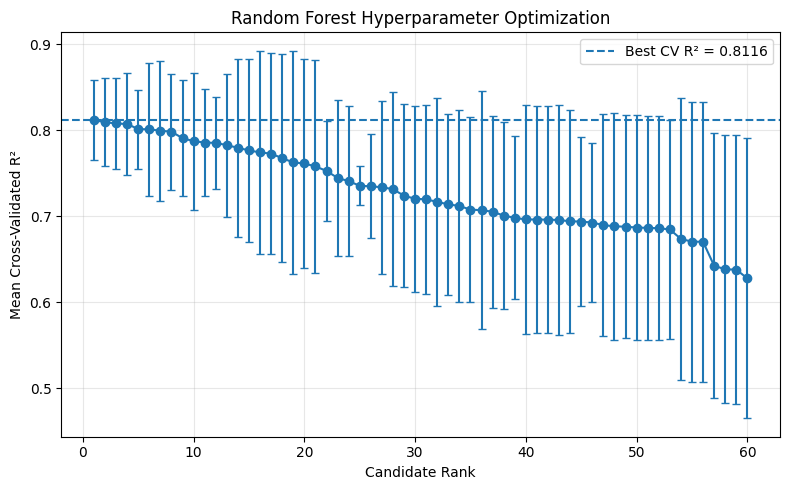

In [ ]:
# ==========================================================
# HYPERPARAMETER OPTIMIZATION PLOT
# ==========================================================

plt.figure(
    figsize=(8, 5)
)

plt.errorbar(

    np.arange(1, len(cv_results_df) + 1),

    cv_results_df["mean_test_score"],

    yerr=cv_results_df["std_test_score"],

    marker="o",

    linestyle="-",

    capsize=3

)

plt.axhline(

    best_cv_r2,

    linestyle="--",

    label=f"Best CV R² = {best_cv_r2:.4f}"

)

plt.xlabel(
    "Candidate Rank"
)

plt.ylabel(
    "Mean Cross-Validated R²"
)

plt.title(
    "Random Forest Hyperparameter Optimization"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# FINAL OPTIMIZED RANDOM FOREST
# ==========================================================

final_rf = rf_search.best_estimator_

In [ ]:
# ==========================================================
# FINAL PREDICTION
# ==========================================================

final_pred_train = final_rf.predict(
    X_rf_train
)

final_pred_test = final_rf.predict(
    X_rf_test
)

In [ ]:
# ==========================================================
# FINAL EVALUATION
# ==========================================================

final_train_metric = evaluate_model(
    y_rf_train,
    final_pred_train
)

final_test_metric = evaluate_model(
    y_rf_test,
    final_pred_test
)

print("=" * 70)
print("FINAL OPTIMIZED RANDOM FOREST")
print("=" * 70)

print("\nTRAIN")
print(final_train_metric)

print("\nTEST")
print(final_test_metric)

FINAL OPTIMIZED RANDOM FOREST

TRAIN
{'R2': 0.9699605106935202, 'RMSE': np.float64(0.0001197590346814253), 'MAE': 4.198182307524135e-05, 'MAPE': np.float64(19.291912079143582)}

TEST
{'R2': 0.9515096403846071, 'RMSE': np.float64(0.00013046909124974618), 'MAE': 9.161127848891665e-05, 'MAPE': np.float64(43.86402047268537)}


In [ ]:
# ==========================================================
# BASELINE VS OPTIMIZED RANDOM FOREST
# ==========================================================

baseline_row = result_df.loc[
    result_df["Model"] == "Random Forest"
].iloc[0]

comparison = pd.DataFrame({

    "Model": [
        "Baseline Random Forest",
        "Optimized Random Forest"
    ],

    "Test_R2": [
        baseline_row["Test_R2"],
        final_test_metric["R2"]
    ],

    "Test_RMSE": [
        baseline_row["Test_RMSE"],
        final_test_metric["RMSE"]
    ],

    "Test_MAE": [
        baseline_row["Test_MAE"],
        final_test_metric["MAE"]
    ],

    "Test_MAPE": [
        baseline_row["Test_MAPE"],
        final_test_metric["MAPE"]
    ]

})

display(
    comparison
)

# ==========================================================
# SAVE OPTIMIZATION RESULTS
# ==========================================================

cv_results_df.to_excel(
    "Release_RandomForest_Hyperparameter_Optimization.xlsx",
    index=False
)

comparison.to_excel(
    "Release_RandomForest_Baseline_vs_Optimized.xlsx",
    index=False
)

,Model,Test_R2,Test_RMSE,Test_MAE,Test_MAPE
0,Baseline Random Forest,0.969854,0.000103,0.000076,40.480106
1,Optimized Random Forest,0.951510,0.000130,0.000092,43.864020


In [ ]:
# ==========================================================
# SAVE FINAL MODEL AND PARAMETERS
# ==========================================================

joblib.dump(
    final_rf,
    "Release_Final_RandomForest.pkl"
)

joblib.dump(
    best_params,
    "Release_Best_RandomForest_Params.pkl"
)

print(
    "\nRandom Forest optimization completed and files saved."
)


Random Forest optimization completed and files saved.


In [ ]:
# PART 26
# EXTRA TREES HYPERPARAMETER OPTIMIZATION
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import (
    GroupKFold,
    RandomizedSearchCV
)

In [ ]:
# ==========================================================
# PREPARE DATA
# ==========================================================

X_et_train = X_train_processed
X_et_test = X_test_processed

y_et_train = np.asarray(y_train).ravel()
y_et_test = np.asarray(y_test).ravel()

In [ ]:
# ==========================================================
# GROUP K-FOLD
# ==========================================================

group_cv = GroupKFold(
    n_splits=5
)

# ==========================================================
# EXTRA TREES BASE ESTIMATOR
# ==========================================================

et = ExtraTreesRegressor(
    random_state=42,
    n_jobs=1
)

# ==========================================================
# HYPERPARAMETER SEARCH SPACE
# ==========================================================

param_distributions = {

    "n_estimators": [
        200, 300, 500, 700, 1000
    ],

    "max_depth": [
        None, 5, 10, 15, 20, 30
    ],

    "max_features": [
        0.3, 0.5, 0.7, 1.0,
        "sqrt", "log2"
    ],

    "min_samples_split": [
        2, 5, 10, 15
    ],

    "min_samples_leaf": [
        1, 2, 4, 6, 8
    ],

    "bootstrap": [
        True, False
    ]

}

# ==========================================================
# RANDOMIZED SEARCH
# ==========================================================

et_search = RandomizedSearchCV(

    estimator=et,

    param_distributions=param_distributions,

    n_iter=60,

    scoring="r2",

    cv=group_cv,

    refit=True,

    random_state=42,

    n_jobs=-1,

    verbose=1,

    return_train_score=True,

    error_score="raise"

)

et_search.fit(

    X_et_train,

    y_et_train,

    groups=train_groups

)

Fitting 5 folds for each of 60 candidates, totalling 300 fits


RandomizedSearchCV(cv=GroupKFold(n_splits=5, random_state=None, shuffle=False),
                   error_score='raise',
                   estimator=ExtraTreesRegressor(n_jobs=1, random_state=42),
                   n_iter=60, n_jobs=-1,
                   param_distributions={'bootstrap': [True, False],
                                        'max_depth': [None, 5, 10, 15, 20, 30],
                                        'max_features': [0.3, 0.5, 0.7, 1.0,
                                                         'sqrt', 'log2'],
                                        'min_samples_leaf': [1, 2, 4, 6, 8],
                                        'min_samples_split': [2, 5, 10, 15],
                                        'n_estimators': [200, 300, 500, 700,
                                                         1000]},
                   random_state=42, return_train_score=True, scoring='r2',
                   verbose=1)

In [ ]:
# ==========================================================
# CROSS-VALIDATION RESULTS
# ==========================================================

cv_results_df = pd.DataFrame(
    et_search.cv_results_
)

cv_results_df = cv_results_df.sort_values(
    by="mean_test_score",
    ascending=False
).reset_index(drop=True)

display(
    cv_results_df[
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "params"
        ]
    ].head(20)
)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
0,1,0.801359,0.066010,0.980752,"{'n_estimators': 500, 'min_samples_split': 2, ..."
1,2,0.795452,0.063279,0.945093,"{'n_estimators': 700, 'min_samples_split': 5, ..."
2,3,0.794354,0.067600,0.883079,"{'n_estimators': 500, 'min_samples_split': 5, ..."
3,4,0.793411,0.067863,0.881520,"{'n_estimators': 500, 'min_samples_split': 5, ..."
4,5,0.788054,0.067515,0.893326,"{'n_estimators': 1000, 'min_samples_split': 10..."
5,6,0.787496,0.116771,0.819614,"{'n_estimators': 200, 'min_samples_split': 2, ..."
6,7,0.784860,0.117469,0.816323,"{'n_estimators': 1000, 'min_samples_split': 5,..."
7,8,0.783449,0.066694,0.874771,"{'n_estimators': 300, 'min_samples_split': 5, ..."
8,9,0.782342,0.118360,0.816097,"{'n_estimators': 300, 'min_samples_split': 10,..."
9,10,0.782040,0.115636,0.813956,"{'n_estimators': 500, 'min_samples_split': 5, ..."


In [ ]:
# ==========================================================
# BEST EXTRA TREES HYPERPARAMETERS
# ==========================================================

best_params = et_search.best_params_
best_cv_r2 = et_search.best_score_

best_cv_std = et_search.cv_results_[
    "std_test_score"
][et_search.best_index_]

print("=" * 70)
print("BEST EXTRA TREES HYPERPARAMETERS")
print("=" * 70)

print("Best Parameters:")
print(best_params)

print("\nBest CV R²:", best_cv_r2)
print("CV R² Std :", best_cv_std)

BEST EXTRA TREES HYPERPARAMETERS
Best Parameters:
{'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 30, 'bootstrap': True}

Best CV R²: 0.8013589010692959
CV R² Std : 0.0660103496232939


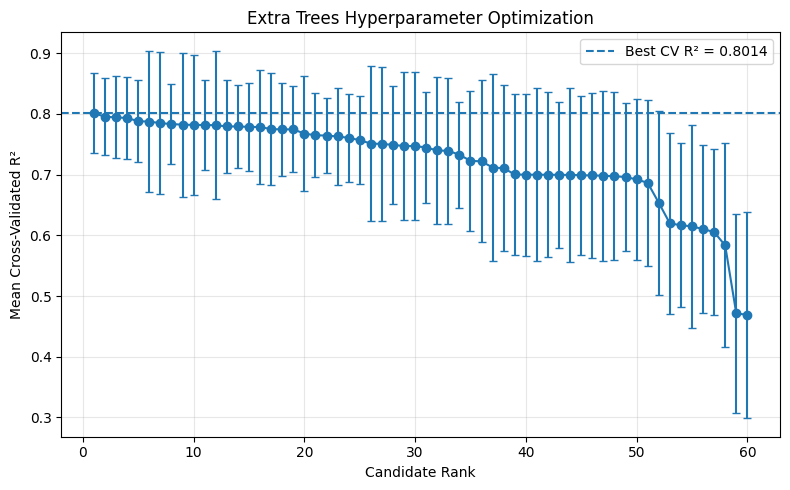

In [ ]:
# ==========================================================
# HYPERPARAMETER OPTIMIZATION PLOT
# ==========================================================

plt.figure(
    figsize=(8, 5)
)

plt.errorbar(

    np.arange(1, len(cv_results_df) + 1),

    cv_results_df["mean_test_score"],

    yerr=cv_results_df["std_test_score"],

    marker="o",

    linestyle="-",

    capsize=3

)

plt.axhline(

    best_cv_r2,

    linestyle="--",

    label=f"Best CV R² = {best_cv_r2:.4f}"

)

plt.xlabel(
    "Candidate Rank"
)

plt.ylabel(
    "Mean Cross-Validated R²"
)

plt.title(
    "Extra Trees Hyperparameter Optimization"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# FINAL OPTIMIZED EXTRA TREES
# ==========================================================

final_et = et_search.best_estimator_

In [ ]:
# ==========================================================
# FINAL PREDICTION
# ==========================================================

final_pred_train = final_et.predict(
    X_et_train
)

final_pred_test = final_et.predict(
    X_et_test
)

In [ ]:
# ==========================================================
# FINAL EVALUATION
# ==========================================================

final_train_metric = evaluate_model(
    y_et_train,
    final_pred_train
)

final_test_metric = evaluate_model(
    y_et_test,
    final_pred_test
)

print("=" * 70)
print("FINAL OPTIMIZED EXTRA TREES")
print("=" * 70)

print("\nTRAIN")
print(final_train_metric)

print("\nTEST")
print(final_test_metric)

FINAL OPTIMIZED EXTRA TREES

TRAIN
{'R2': 0.9830318218400481, 'RMSE': np.float64(9.000769124621703e-05), 'MAE': 3.741247046221186e-05, 'MAPE': np.float64(16.290962295239257)}

TEST
{'R2': 0.9598107285943281, 'RMSE': np.float64(0.0001187777246188346), 'MAE': 7.748771235407308e-05, 'MAPE': np.float64(36.82505362775959)}


In [ ]:
# ==========================================================
# BASELINE VS OPTIMIZED EXTRA TREES
# ==========================================================

baseline_row = result_df.loc[
    result_df["Model"] == "Extra Trees"
].iloc[0]

comparison = pd.DataFrame({

    "Model": [
        "Baseline Extra Trees",
        "Optimized Extra Trees"
    ],

    "Test_R2": [
        baseline_row["Test_R2"],
        final_test_metric["R2"]
    ],

    "Test_RMSE": [
        baseline_row["Test_RMSE"],
        final_test_metric["RMSE"]
    ],

    "Test_MAE": [
        baseline_row["Test_MAE"],
        final_test_metric["MAE"]
    ],

    "Test_MAPE": [
        baseline_row["Test_MAPE"],
        final_test_metric["MAPE"]
    ]

})

display(
    comparison
)

,Model,Test_R2,Test_RMSE,Test_MAE,Test_MAPE
0,Baseline Extra Trees,0.940045,0.000145,0.000084,35.315976
1,Optimized Extra Trees,0.959811,0.000119,0.000077,36.825054


In [ ]:
# ==========================================================
# SAVE OPTIMIZATION RESULTS
# ==========================================================

cv_results_df.to_excel(
    "Release_ExtraTrees_Hyperparameter_Optimization.xlsx",
    index=False
)

comparison.to_excel(
    "Release_ExtraTrees_Baseline_vs_Optimized.xlsx",
    index=False
)

In [ ]:
# ==========================================================
# SAVE FINAL MODEL AND PARAMETERS
# ==========================================================

joblib.dump(
    final_et,
    "Release_Final_ExtraTrees.pkl"
)

joblib.dump(
    best_params,
    "Release_Best_ExtraTrees_Params.pkl"
)

print(
    "\nExtra Trees optimization completed and files saved."
)


Extra Trees optimization completed and files saved.


In [ ]:
# ==========================================================
# PART 27
# XGBOOST HYPERPARAMETER OPTIMIZATION
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from xgboost import XGBRegressor

from sklearn.model_selection import (
    GroupKFold,
    RandomizedSearchCV
)

# ==========================================================
# PREPARE DATA
# ==========================================================

X_xgb_train = X_train_processed
X_xgb_test = X_test_processed

y_xgb_train = np.asarray(y_train).ravel()
y_xgb_test = np.asarray(y_test).ravel()

In [ ]:
# ==========================================================
# GROUP K-FOLD
# ==========================================================

group_cv = GroupKFold(
    n_splits=5
)

# ==========================================================
# XGBOOST BASE ESTIMATOR
# ==========================================================

xgb = XGBRegressor(

    objective="reg:squarederror",

    eval_metric="rmse",

    random_state=42,

    verbosity=0,

    n_jobs=1

)

# ==========================================================
# HYPERPARAMETER SEARCH SPACE
# ==========================================================

param_distributions = {

    "n_estimators": [
        200, 300, 500, 700, 1000
    ],

    "learning_rate": [
        0.01, 0.02, 0.03, 0.05, 0.1
    ],

    "max_depth": [
        2, 3, 4, 5, 6, 8
    ],

    "min_child_weight": [
        1, 2, 3, 5, 7
    ],

    "subsample": [
        0.6, 0.7, 0.8, 0.9, 1.0
    ],

    "colsample_bytree": [
        0.5, 0.6, 0.7, 0.8, 0.9, 1.0
    ],

    "gamma": [
        0, 0.1, 0.3, 0.5, 1, 2
    ],

    "reg_alpha": [
        0, 0.001, 0.01, 0.1, 1
    ],

    "reg_lambda": [
        0.1, 0.5, 1, 2, 5, 10
    ]

}

# ==========================================================
# RANDOMIZED SEARCH
# ==========================================================

xgb_search = RandomizedSearchCV(

    estimator=xgb,

    param_distributions=param_distributions,

    n_iter=80,

    scoring="r2",

    cv=group_cv,

    refit=True,

    random_state=42,

    n_jobs=-1,

    verbose=1,

    return_train_score=True,

    error_score="raise"

)

xgb_search.fit(

    X_xgb_train,

    y_xgb_train,

    groups=train_groups

)

# ==========================================================
# CROSS-VALIDATION RESULTS
# ==========================================================

cv_results_df = pd.DataFrame(
    xgb_search.cv_results_
)

cv_results_df = cv_results_df.sort_values(
    by="mean_test_score",
    ascending=False
).reset_index(drop=True)

display(
    cv_results_df[
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "params"
        ]
    ].head(20)
)

Fitting 5 folds for each of 80 candidates, totalling 400 fits


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
0,1,0.781414,0.098454,0.900106,"{'subsample': 0.7, 'reg_lambda': 0.1, 'reg_alp..."
1,2,0.768531,0.120392,0.916084,"{'subsample': 0.8, 'reg_lambda': 0.5, 'reg_alp..."
2,3,0.761655,0.126968,0.936087,"{'subsample': 0.6, 'reg_lambda': 0.5, 'reg_alp..."
3,4,0.757023,0.133834,0.916349,"{'subsample': 0.9, 'reg_lambda': 2, 'reg_alpha..."
4,5,0.731643,0.164626,0.889265,"{'subsample': 1.0, 'reg_lambda': 0.5, 'reg_alp..."
5,6,0.718424,0.180223,0.862209,"{'subsample': 0.9, 'reg_lambda': 2, 'reg_alpha..."
6,7,0.698653,0.167621,0.856093,"{'subsample': 0.6, 'reg_lambda': 10, 'reg_alph..."
7,8,0.694303,0.176106,0.886118,"{'subsample': 0.6, 'reg_lambda': 0.1, 'reg_alp..."
8,9,0.675996,0.190009,0.823989,"{'subsample': 1.0, 'reg_lambda': 5, 'reg_alpha..."
9,10,0.661992,0.205239,0.796674,"{'subsample': 0.8, 'reg_lambda': 10, 'reg_alph..."


In [ ]:
# ==========================================================
# BEST XGBOOST HYPERPARAMETERS
# ==========================================================

best_params = xgb_search.best_params_

best_cv_r2 = xgb_search.best_score_

best_cv_std = xgb_search.cv_results_[
    "std_test_score"
][xgb_search.best_index_]

print("=" * 70)
print("BEST XGBOOST HYPERPARAMETERS")
print("=" * 70)

print("Best Parameters:")

for param, value in best_params.items():
    print(f"{param}: {value}")

print("\nBest CV R²:", best_cv_r2)
print("CV R² Std :", best_cv_std)

BEST XGBOOST HYPERPARAMETERS
Best Parameters:
subsample: 0.7
reg_lambda: 0.1
reg_alpha: 0
n_estimators: 700
min_child_weight: 7
max_depth: 8
learning_rate: 0.1
gamma: 0
colsample_bytree: 0.6

Best CV R²: 0.78141361821222
CV R² Std : 0.09845366573954696


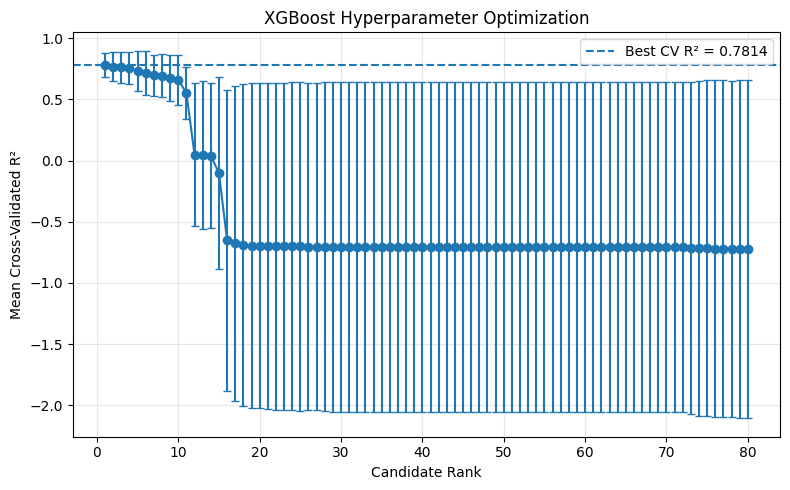

In [ ]:
# ==========================================================
# HYPERPARAMETER OPTIMIZATION PLOT
# ==========================================================

plt.figure(
    figsize=(8, 5)
)

plt.errorbar(

    np.arange(1, len(cv_results_df) + 1),

    cv_results_df["mean_test_score"],

    yerr=cv_results_df["std_test_score"],

    marker="o",

    linestyle="-",

    capsize=3

)

plt.axhline(

    best_cv_r2,

    linestyle="--",

    label=f"Best CV R² = {best_cv_r2:.4f}"

)

plt.xlabel(
    "Candidate Rank"
)

plt.ylabel(
    "Mean Cross-Validated R²"
)

plt.title(
    "XGBoost Hyperparameter Optimization"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [ ]:
# ==========================================================
# FINAL OPTIMIZED XGBOOST
# ==========================================================

final_xgb = xgb_search.best_estimator_

In [ ]:
# ==========================================================
# FINAL PREDICTION
# ==========================================================

final_pred_train = final_xgb.predict(
    X_xgb_train
)

final_pred_test = final_xgb.predict(
    X_xgb_test
)

In [ ]:
# ==========================================================
# FINAL EVALUATION
# ==========================================================

final_train_metric = evaluate_model(
    y_xgb_train,
    final_pred_train
)

final_test_metric = evaluate_model(
    y_xgb_test,
    final_pred_test
)

print("=" * 70)
print("FINAL OPTIMIZED XGBOOST")
print("=" * 70)

print("\nTRAIN")
print(final_train_metric)

print("\nTEST")
print(final_test_metric)

FINAL OPTIMIZED XGBOOST

TRAIN
{'R2': 0.9246197342245137, 'RMSE': np.float64(0.00018971027184368385), 'MAE': 0.00010691523156978244, 'MAPE': np.float64(46.6025929763849)}

TEST
{'R2': 0.907361956093751, 'RMSE': np.float64(0.0001803327572568573), 'MAE': 0.00012797055640959687, 'MAPE': np.float64(31.79055657853816)}


In [ ]:
# ==========================================================
# BASELINE VS OPTIMIZED XGBOOST
# ==========================================================

baseline_row = result_df.loc[
    result_df["Model"] == "XGBoost"
].iloc[0]

comparison = pd.DataFrame({

    "Model": [
        "Baseline XGBoost",
        "Optimized XGBoost"
    ],

    "Test_R2": [
        baseline_row["Test_R2"],
        final_test_metric["R2"]
    ],

    "Test_RMSE": [
        baseline_row["Test_RMSE"],
        final_test_metric["RMSE"]
    ],

    "Test_MAE": [
        baseline_row["Test_MAE"],
        final_test_metric["MAE"]
    ],

    "Test_MAPE": [
        baseline_row["Test_MAPE"],
        final_test_metric["MAPE"]
    ]

})

display(
    comparison
)

,Model,Test_R2,Test_RMSE,Test_MAE,Test_MAPE
0,Baseline XGBoost,0.896352,0.000191,0.000155,46.466861
1,Optimized XGBoost,0.907362,0.000180,0.000128,31.790557


In [ ]:
# ==========================================================
# SAVE OPTIMIZATION RESULTS
# ==========================================================

cv_results_df.to_excel(
    "Release_XGBoost_Hyperparameter_Optimization.xlsx",
    index=False
)

comparison.to_excel(
    "Release_XGBoost_Baseline_vs_Optimized.xlsx",
    index=False
)


,CV_Rank,Model,CV_R2_Mean,CV_R2_Std,Test_R2,Test_RMSE,Test_MAE,Test_MAPE,Best_Hyperparameters,Saved_Model
0,1,Ridge,0.888961,0.084806,0.976504,0.000091,0.000076,41.447009,{'alpha': 177.82794100389228},True
1,2,PLSR,0.853785,0.104106,0.963203,0.000114,0.000097,50.352050,{'n_components': 4},True
2,3,Random Forest,0.811648,0.046301,0.951510,0.000130,0.000092,43.864020,"{'n_estimators': 200, 'min_samples_split': 5, ...",True
3,4,Extra Trees,0.801359,0.066010,0.959811,0.000119,0.000077,36.825054,"{'n_estimators': 500, 'min_samples_split': 2, ...",True
4,5,XGBoost,0.781414,0.098454,0.907362,0.000180,0.000128,31.790557,"{'subsample': 0.7, 'reg_lambda': 0.1, 'reg_alp...",False


GLOBAL BEST MODEL
Model: Ridge
Mean CV R²: 0.8889612565042275
CV R² Std: 0.08480572265196518

Best Hyperparameters:
{'alpha': 177.82794100389228}

Best model loaded: Release_Final_Ridge.pkl


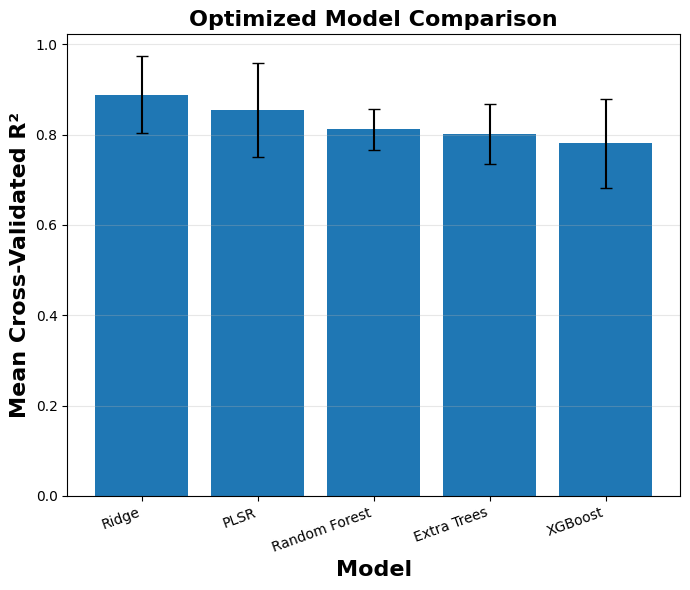


Global comparison completed.
Saved: Release_All_5_Models_Optimization_Summary.xlsx


In [ ]:

# ==========================================================
# PART 28
# GLOBAL BEST MODEL SELECTION
# 5 OPTIMIZED MODELS
# ==========================================================

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# MODEL CONFIGURATION
# ==========================================================

model_files = {

    "Ridge": {
        "cv_file": "Release_Ridge_Hyperparameter_Optimization.xlsx",
        "comparison_file": "Release_Ridge_Baseline_vs_Optimized.xlsx",
        "params_file": "Release_Best_Ridge_Alpha.pkl",
        "model_file": "Release_Final_Ridge.pkl"
    },

    "PLSR": {
        "cv_file": "Release_PLSR_Component_Optimization.xlsx",
        "comparison_file": "Release_PLSR_Baseline_vs_Optimized.xlsx",
        "params_file": "Release_Best_PLS_Components.pkl",
        "model_file": "Release_Final_PLSR.pkl"
    },

    "Random Forest": {
        "cv_file": "Release_RandomForest_Hyperparameter_Optimization.xlsx",
        "comparison_file": "Release_RandomForest_Baseline_vs_Optimized.xlsx",
        "params_file": "Release_Best_RandomForest_Params.pkl",
        "model_file": "Release_Final_RandomForest.pkl"
    },

    "Extra Trees": {
        "cv_file": "Release_ExtraTrees_Hyperparameter_Optimization.xlsx",
        "comparison_file": "Release_ExtraTrees_Baseline_vs_Optimized.xlsx",
        "params_file": "Release_Best_ExtraTrees_Params.pkl",
        "model_file": "Release_Final_ExtraTrees.pkl"
    },

    "XGBoost": {
        "cv_file": "Release_XGBoost_Hyperparameter_Optimization.xlsx",
        "comparison_file": "Release_XGBoost_Baseline_vs_Optimized.xlsx",
        "params_file": "Release_Best_XGBoost_Params.pkl",
        "model_file": "Release_Final_XGBoost.pkl"
    }

}

# ==========================================================
# EXTRACT BEST CV RESULTS
# ==========================================================

summary = []
best_params_dict = {}

for model_name, files in model_files.items():

    if not os.path.exists(files["cv_file"]):
        print(f"WARNING: Missing CV file for {model_name}")
        continue

    cv_df = pd.read_excel(files["cv_file"])

    # Identify the CV score column
    score_col = next(
        (
            col for col in [
                "Mean_CV_R2",
                "mean_test_score"
            ]
            if col in cv_df.columns
        ),
        None
    )

    if score_col is None:
        print(f"WARNING: No CV score column for {model_name}")
        continue

    cv_df[score_col] = pd.to_numeric(
        cv_df[score_col],
        errors="coerce"
    )

    cv_df = cv_df.dropna(
        subset=[score_col]
    )

    if cv_df.empty:
        continue

    best_idx = cv_df[score_col].idxmax()
    best_row = cv_df.loc[best_idx]

    cv_mean = float(best_row[score_col])

    std_col = (
        "Std_CV_R2"
        if "Std_CV_R2" in cv_df.columns
        else "std_test_score"
    )

    cv_std = (
        float(best_row[std_col])
        if std_col in cv_df.columns
        and pd.notna(best_row[std_col])
        else np.nan
    )

    # Load saved best hyperparameters
    if os.path.exists(files["params_file"]):

        best_params = joblib.load(
            files["params_file"]
        )

        if model_name == "Ridge":
            best_params = {
                "alpha": float(best_params)
            }

        elif model_name == "PLSR":
            best_params = {
                "n_components": int(best_params)
            }

    else:
        # Fallback: recover parameters from CV results
        if "params" in cv_df.columns:
            best_params = best_row["params"]

        elif model_name == "Ridge":
            best_params = {
                "alpha": float(best_row["alpha"])
            }

        elif model_name == "PLSR":
            best_params = {
                "n_components": int(
                    best_row["n_components"]
                )
            }

        else:
            best_params = None

    best_params_dict[model_name] = best_params

    # Extract optimized test metrics
    test_metrics = {
        "Test_R2": np.nan,
        "Test_RMSE": np.nan,
        "Test_MAE": np.nan,
        "Test_MAPE": np.nan
    }

    comparison_file = files["comparison_file"]

    if os.path.exists(comparison_file):

        comparison_df = pd.read_excel(
            comparison_file
        )

        optimized_rows = comparison_df[
            comparison_df["Model"].astype(str).str.startswith(
                "Optimized "
            )
        ]

        if not optimized_rows.empty:

            row = optimized_rows.iloc[0]

            for metric in test_metrics:
                if metric in comparison_df.columns:
                    test_metrics[metric] = row[metric]

    summary.append({

        "Model": model_name,

        "CV_R2_Mean": cv_mean,

        "CV_R2_Std": cv_std,

        **test_metrics,

        "Best_Hyperparameters": str(best_params),

        "Saved_Model": os.path.exists(
            files["model_file"]
        )

    })

# ==========================================================
# GLOBAL MODEL COMPARISON
# ==========================================================

summary_df = pd.DataFrame(summary)

if summary_df.empty:
    raise FileNotFoundError(
        "No optimization results found. "
        "Check the five optimization output files."
    )

summary_df = summary_df.sort_values(
    "CV_R2_Mean",
    ascending=False
).reset_index(drop=True)

summary_df.insert(
    0,
    "CV_Rank",
    np.arange(1, len(summary_df) + 1)
)

display(summary_df)

# ==========================================================
# SELECT BEST MODEL USING CV R²
# ==========================================================

best_row = summary_df.iloc[0]

best_model_name = best_row["Model"]
best_model_params = best_params_dict[best_model_name]

print("=" * 70)
print("GLOBAL BEST MODEL")
print("=" * 70)

print("Model:", best_model_name)
print("Mean CV R²:", best_row["CV_R2_Mean"])
print("CV R² Std:", best_row["CV_R2_Std"])

print("\nBest Hyperparameters:")
print(best_model_params)

# ==========================================================
# LOAD BEST MODEL
# ==========================================================

best_model_path = model_files[
    best_model_name
]["model_file"]

if os.path.exists(best_model_path):

    best_model = joblib.load(
        best_model_path
    )

    print("\nBest model loaded:", best_model_path)

else:

    best_model = None

    print("\nWARNING: Best model file not found.")

# ==========================================================
# VISUALIZE CV PERFORMANCE
# ==========================================================

plt.figure(figsize=(7, 6))

plt.bar(
    summary_df["Model"],
    summary_df["CV_R2_Mean"],
    yerr=summary_df["CV_R2_Std"],
    capsize=4
)

plt.ylabel("Mean Cross-Validated R²", fontsize=16, fontweight='bold')
plt.xlabel("Model", fontsize=16, fontweight='bold')
plt.title("Optimized Model Comparison", fontsize=16, fontweight='bold')
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================================
# SAVE GLOBAL RESULTS
# ==========================================================

summary_df.to_excel(
    "Release_All_5_Models_Optimization_Summary.xlsx",
    index=False
)

joblib.dump(
    best_model_name,
    "Release_Global_Best_Model_Name.pkl"
)

joblib.dump(
    best_model_params,
    "Release_Global_Best_Model_Params.pkl"
)

print("\nGlobal comparison completed.")
print("Saved: Release_All_5_Models_Optimization_Summary.xlsx")


In [ ]:
import pandas as pd

# Membaca dan menampilkan hasil K-Fold global untuk semua model
if os.path.exists('Release_All_5_Models_Optimization_Summary.xlsx'):
    summary_kfold = pd.read_excel('Release_All_5_Models_Optimization_Summary.xlsx')
    print("=== RINGKASAN STABILITAS K-FOLD (R² MEAN & STD) UNTUK SETIAP MODEL ===")
    display(summary_kfold[['Model', 'CV_R2_Mean', 'CV_R2_Std', 'Test_R2', 'Best_Hyperparameters']])
else:
    print("File summary belum ditemukan. Silakan jalankan modul evaluasi terlebih dahulu.")

=== RINGKASAN STABILITAS K-FOLD (R² MEAN & STD) UNTUK SETIAP MODEL ===


,Model,CV_R2_Mean,CV_R2_Std,Test_R2,Best_Hyperparameters
0,Ridge,0.888961,0.084806,0.976504,{'alpha': 177.82794100389228}
1,PLSR,0.853785,0.104106,0.963203,{'n_components': 4}
2,Random Forest,0.811648,0.046301,0.951510,"{'n_estimators': 200, 'min_samples_split': 5, ..."
3,Extra Trees,0.801359,0.066010,0.959811,"{'n_estimators': 500, 'min_samples_split': 2, ..."
4,XGBoost,0.781414,0.098454,0.907362,"{'subsample': 0.7, 'reg_lambda': 0.1, 'reg_alp..."


In [ ]:
# 1. Definisikan ulang parameter terbaik dari hasil optimasi sebelumnya
best_configs = {
    "PLSR": PLSRegression(n_components=30),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=0.05623413251903491))
    ]),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, min_samples_split=2, min_samples_leaf=2,
        max_features='sqrt', max_depth=20, bootstrap=False, random_state=42, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200, min_samples_split=2, min_samples_leaf=1,
        max_features=0.3, max_depth=5, bootstrap=True, random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        objective="reg:squarederror", subsample=0.6, reg_lambda=10, reg_alpha=0.001,
        n_estimators=300, min_child_weight=3, max_depth=8, learning_rate=0.01,
        gamma=0, colsample_bytree=0.7, random_state=42, n_jobs=-1
    )
}

# 2. Setup GroupKFold
group_cv = GroupKFold(n_splits=5)
fold_details = []

# 3. Hitung score per fold untuk masing-masing model
for model_name, model in best_configs.items():
    # Menghitung skor R² pada tiap lipatan
    scores = cross_val_score(
        model,
        X_train_processed,
        np.asarray(y_train).ravel(),
        groups=train_groups,
        cv=group_cv,
        scoring="r2",
        n_jobs=-1
    )

    fold_details.append({
        "Model": model_name,
        "Fold 1 R²": scores[0],
        "Fold 2 R²": scores[1],
        "Fold 3 R²": scores[2],
        "Fold 4 R²": scores[3],
        "Fold 5 R²": scores[4],
        "Mean R²": scores.mean(),
        "Std Dev (Stabilitas)": scores.std()
    })

# 4. Tampilkan dalam bentuk DataFrame
df_fold_details = pd.DataFrame(fold_details)
print("=== DETAIL AKURASI R² PER FOLD UNTUK PENGUJIAN STABILITAS ===")
display(df_fold_details.round(6))

=== DETAIL AKURASI R² PER FOLD UNTUK PENGUJIAN STABILITAS ===


,Model,Fold 1 R²,Fold 2 R²,Fold 3 R²,Fold 4 R²,Fold 5 R²,Mean R²,Std Dev (Stabilitas)
0,PLSR,0.893228,0.667194,0.792642,0.410643,0.980324,0.748806,0.198693
1,Ridge,0.898596,0.780909,0.738745,0.559670,0.911093,0.777803,0.127651
2,Random Forest,0.799409,0.590809,0.806519,0.837713,0.634199,0.733730,0.100754
3,Extra Trees,0.825100,0.637955,0.836366,0.831513,0.742488,0.774685,0.076560
4,XGBoost,0.350637,0.791346,0.770811,0.266972,0.581166,0.552186,0.213449


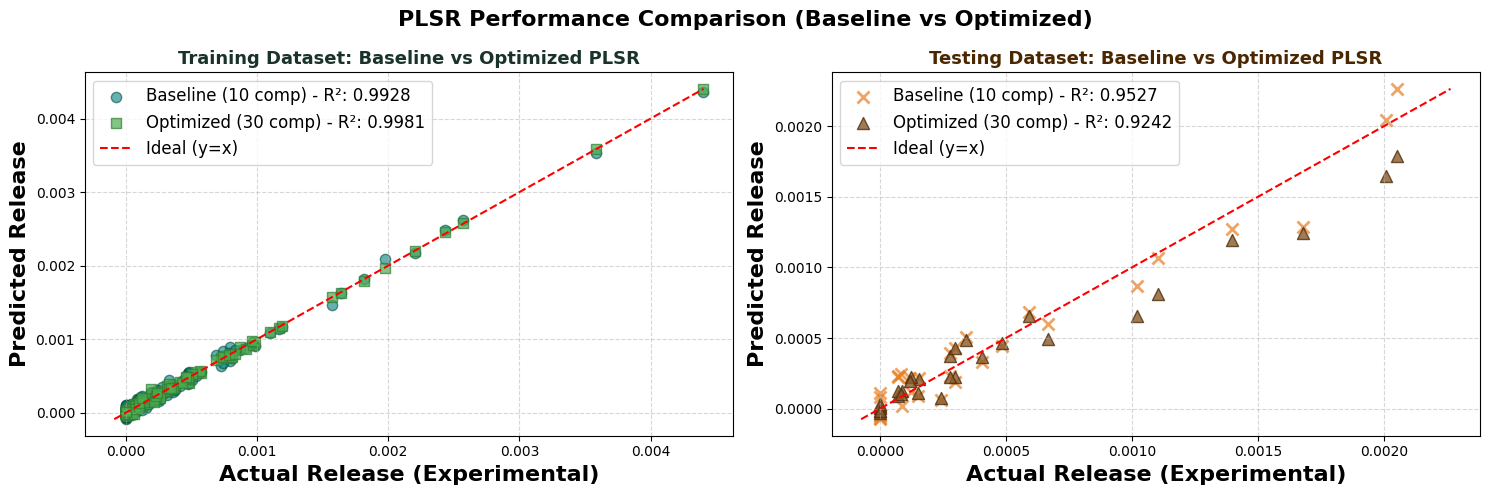

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import r2_score

# 1. Pastikan model baseline dan optimized dilatih
baseline_plsr = PLSRegression(n_components=10)
baseline_plsr.fit(X_train_processed, y_train)

optimized_plsr = PLSRegression(n_components=30)
optimized_plsr.fit(X_train_processed, y_train)

# 2. Dapatkan prediksi untuk kedua model
y_train_pred_base = baseline_plsr.predict(X_train_processed).ravel()
y_test_pred_base = baseline_plsr.predict(X_test_processed).ravel()

y_train_pred_opt = optimized_plsr.predict(X_train_processed).ravel()
y_test_pred_opt = optimized_plsr.predict(X_test_processed).ravel()

# 3. Hitung skor R² untuk masing-masing kondisi
r2_train_base = r2_score(y_train, y_train_pred_base)
r2_train_opt = r2_score(y_train, y_train_pred_opt)

r2_test_base = r2_score(y_test, y_test_pred_base)
r2_test_opt = r2_score(y_test, y_test_pred_opt)

# 4. Membuat subplot terpisah untuk Training dan Testing
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- SUBPLOT 1: TRAINING DATASET (Warm Green-Blue Nuance) ---
axes[0].scatter(y_train, y_train_pred_base, color='#008080', alpha=0.6, marker='o', s=55, edgecolors='#004d40',
                label=f'Baseline (10 comp) - R²: {r2_train_base:.4f}')
axes[0].scatter(y_train, y_train_pred_opt, color='#4caf50', alpha=0.7, marker='s', s=55, edgecolors='#2e7d32',
                label=f'Optimized (30 comp) - R²: {r2_train_opt:.4f}')

min_train = min(np.min(y_train), np.min(y_train_pred_base), np.min(y_train_pred_opt))
max_train = max(np.max(y_train), np.max(y_train_pred_base), np.max(y_train_pred_opt))
axes[0].plot([min_train, max_train], [min_train, max_train], 'r--', lw=1.5, label='Ideal (y=x)')
axes[0].set_xlabel('Actual Release (Experimental)', fontsize=16, fontweight='bold')
axes[0].set_ylabel('Predicted Release', fontsize=16, fontweight='bold')
axes[0].set_title('Training Dataset: Baseline vs Optimized PLSR', fontsize=13, fontweight='bold', color='#1a332a')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper left', fontsize=12)

# --- SUBPLOT 2: TESTING DATASET (Orange-Brown Nuance) ---
axes[1].scatter(y_test, y_test_pred_base, color='#e67e22', alpha=0.7, marker='x', s=75, linewidths=2,
                label=f'Baseline (10 comp) - R²: {r2_test_base:.4f}')
axes[1].scatter(y_test, y_test_pred_opt, color='#8b5a2b', alpha=0.8, marker='^', s=75, edgecolors='#4e2f0f',
                label=f'Optimized (30 comp) - R²: {r2_test_opt:.4f}')

min_test = min(np.min(y_test), np.min(y_test_pred_base), np.min(y_test_pred_opt))
max_test = max(np.max(y_test), np.max(y_test_pred_base), np.max(y_test_pred_opt))
axes[1].plot([min_test, max_test], [min_test, max_test], 'r--', lw=1.5, label='Ideal (y=x)')
axes[1].set_xlabel('Actual Release (Experimental)', fontsize=16, fontweight='bold')
axes[1].set_ylabel('Predicted Release', fontsize=16, fontweight='bold')
axes[1].set_title('Testing Dataset: Baseline vs Optimized PLSR', fontsize=13, fontweight='bold', color='#4a2700')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper left', fontsize=12)

plt.suptitle('PLSR Performance Comparison (Baseline vs Optimized)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

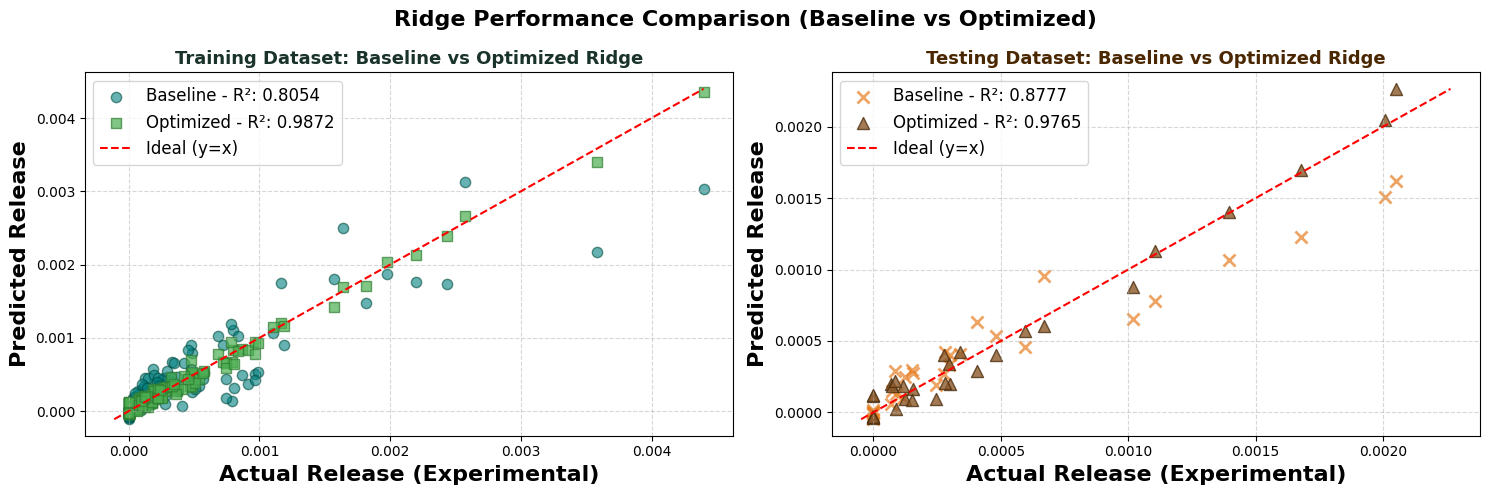

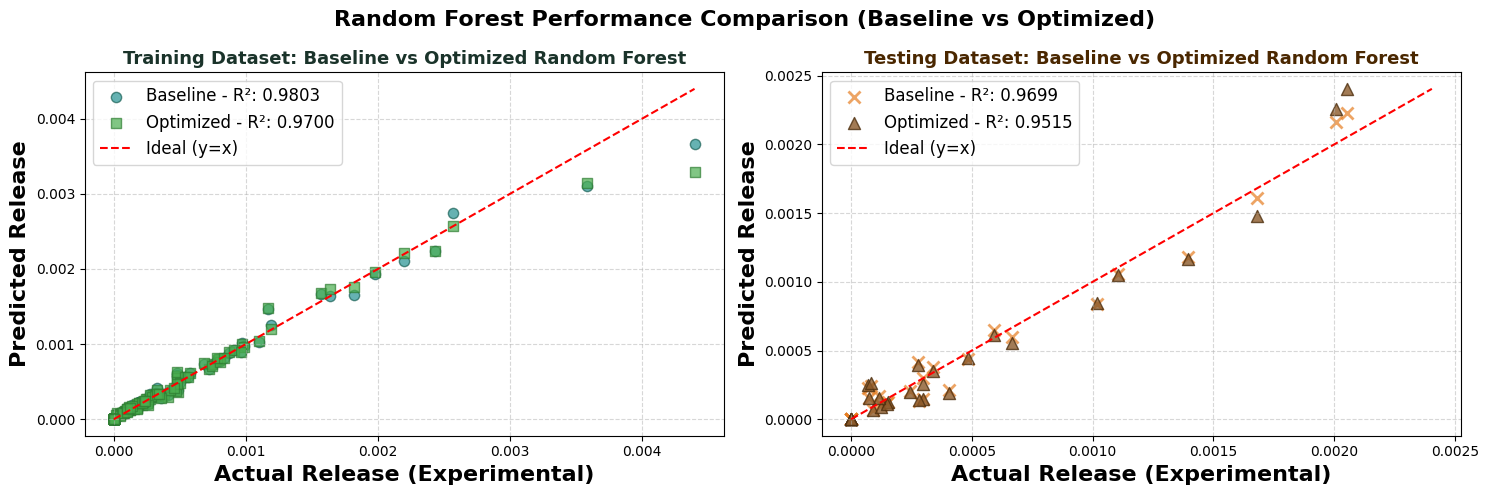

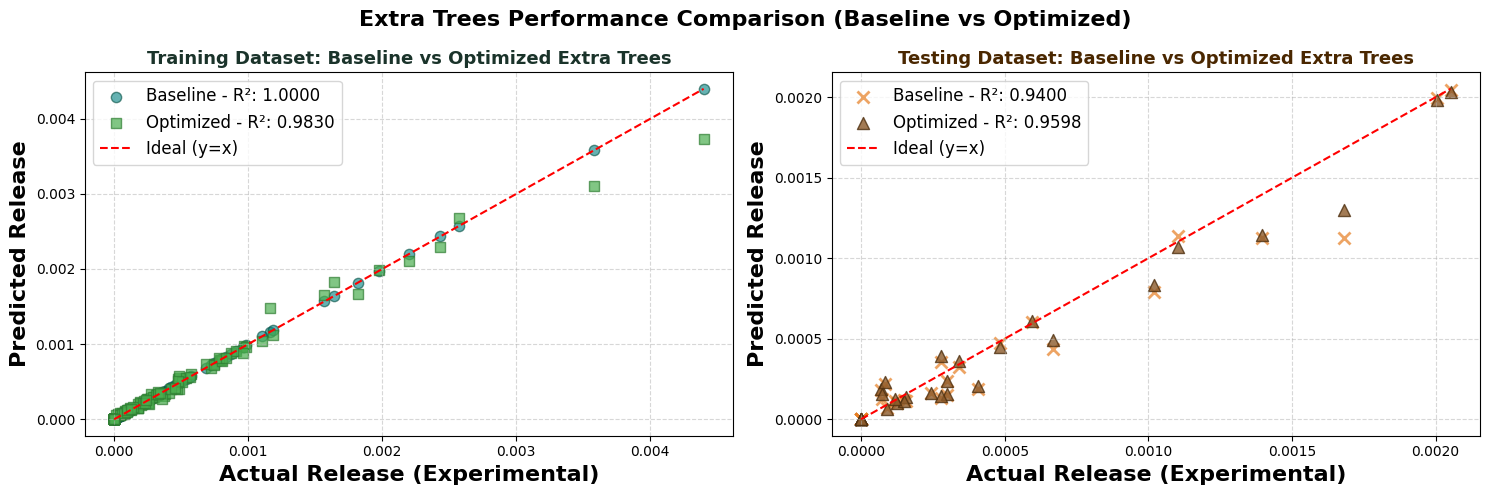

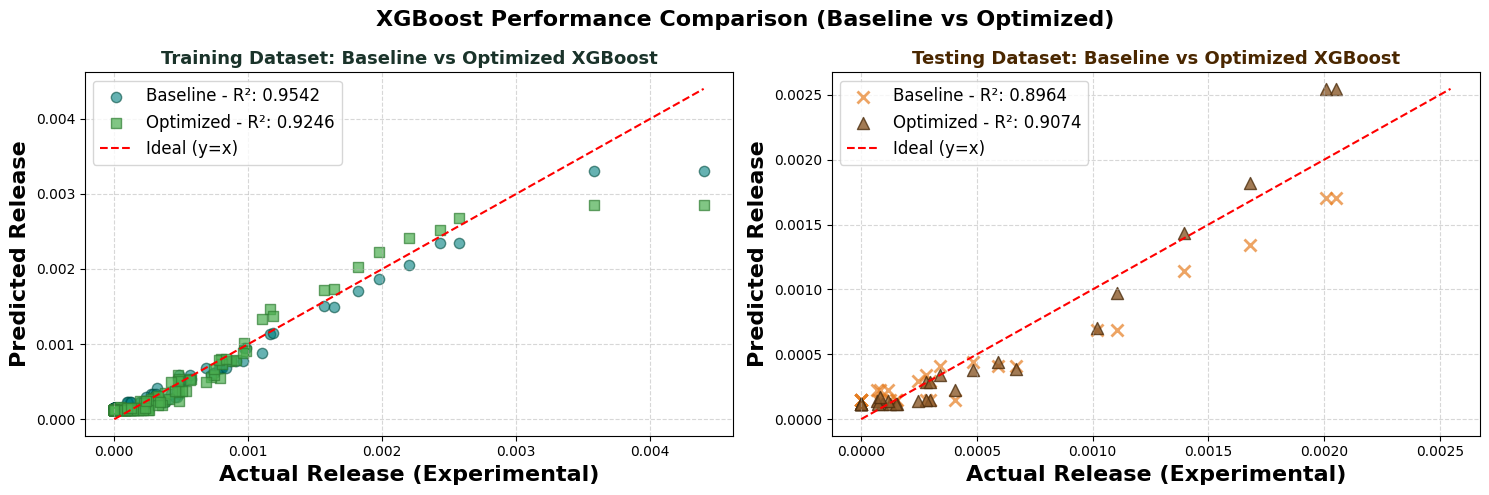

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import joblib
from sklearn.metrics import r2_score

# 1. Definisikan model-model yang akan divisualisasikan
other_models = ["Ridge", "Random Forest", "Extra Trees", "XGBoost"]

# 2. Iterasi untuk setiap model guna menghasilkan plot perbandingan terpisah
for model_name in other_models:
    # Dapatkan prediksi Baseline dari dictionary 'predictions' yang sudah dihitung di awal
    pred_train_base = predictions[model_name]["train"].ravel()
    pred_test_base = predictions[model_name]["test"].ravel()

    # Gunakan objek model dari memori jika tersedia, jika tidak load dari file
    if model_name == "Ridge":
        opt_model = final_ridge if 'final_ridge' in globals() else joblib.load("Release_Final_Ridge.pkl")
        pred_train_opt = opt_model.predict(X_train_processed).ravel()
        pred_test_opt = opt_model.predict(X_test_processed).ravel()
    elif model_name == "Random Forest":
        opt_model = final_rf if 'final_rf' in globals() else joblib.load("Release_Final_RandomForest.pkl")
        pred_train_opt = opt_model.predict(X_train_processed).ravel()
        pred_test_opt = opt_model.predict(X_test_processed).ravel()
    elif model_name == "Extra Trees":
        opt_model = final_et if 'final_et' in globals() else joblib.load("Release_Final_ExtraTrees.pkl")
        pred_train_opt = opt_model.predict(X_train_processed).ravel()
        pred_test_opt = opt_model.predict(X_test_processed).ravel()
    elif model_name == "XGBoost":
        opt_model = final_xgb if 'final_xgb' in globals() else joblib.load("Release_Final_XGBoost.pkl")
        pred_train_opt = opt_model.predict(X_train_processed).ravel()
        pred_test_opt = opt_model.predict(X_test_processed).ravel()

    # Hitung skor R² untuk Baseline dan Optimized
    r2_train_base = r2_score(y_train, pred_train_base)
    r2_train_opt = r2_score(y_train, pred_train_opt)

    r2_test_base = r2_score(y_test, pred_test_base)
    r2_test_opt = r2_score(y_test, pred_test_opt)

    # 3. Membuat subplot terpisah untuk Training dan Testing
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # --- SUBPLOT 1: TRAINING DATASET (Warm Green-Blue Nuance) ---
    axes[0].scatter(y_train, pred_train_base, color='#008080', alpha=0.6, marker='o', s=55, edgecolors='#004d40',
                    label=f'Baseline - R²: {r2_train_base:.4f}')
    axes[0].scatter(y_train, pred_train_opt, color='#4caf50', alpha=0.7, marker='s', s=55, edgecolors='#2e7d32',
                    label=f'Optimized - R²: {r2_train_opt:.4f}')

    min_train = min(np.min(y_train), np.min(pred_train_base), np.min(pred_train_opt))
    max_train = max(np.max(y_train), np.max(pred_train_base), np.max(pred_train_opt))
    axes[0].plot([min_train, max_train], [min_train, max_train], 'r--', lw=1.5, label='Ideal (y=x)')
    axes[0].set_xlabel('Actual Release (Experimental)', fontsize=16, fontweight='bold')
    axes[0].set_ylabel('Predicted Release', fontsize=16, fontweight='bold')
    axes[0].set_title(f'Training Dataset: Baseline vs Optimized {model_name}', fontsize=13, fontweight='bold', color='#1a332a')
    axes[0].grid(True, linestyle='--', alpha=0.5)
    axes[0].legend(loc='upper left', fontsize=12)

    # --- SUBPLOT 2: TESTING DATASET (Orange-Brown Nuance) ---
    axes[1].scatter(y_test, pred_test_base, color='#e67e22', alpha=0.7, marker='x', s=75, linewidths=2,
                    label=f'Baseline - R²: {r2_test_base:.4f}')
    axes[1].scatter(y_test, pred_test_opt, color='#8b5a2b', alpha=0.8, marker='^', s=75, edgecolors='#4e2f0f',
                    label=f'Optimized - R²: {r2_test_opt:.4f}')

    min_test = min(np.min(y_test), np.min(pred_test_base), np.min(pred_test_opt))
    max_test = max(np.max(y_test), np.max(pred_test_base), np.max(pred_test_opt))
    axes[1].plot([min_test, max_test], [min_test, max_test], 'r--', lw=1.5, label='Ideal (y=x)')
    axes[1].set_xlabel('Actual Release (Experimental)', fontsize=16, fontweight='bold')
    axes[1].set_ylabel('Predicted Release', fontsize=16, fontweight='bold')
    axes[1].set_title(f'Testing Dataset: Baseline vs Optimized {model_name}', fontsize=13, fontweight='bold', color='#4a2700')
    axes[1].grid(True, linestyle='--', alpha=0.5)
    axes[1].legend(loc='upper left', fontsize=12)

    plt.suptitle(f'{model_name} Performance Comparison (Baseline vs Optimized)', fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()


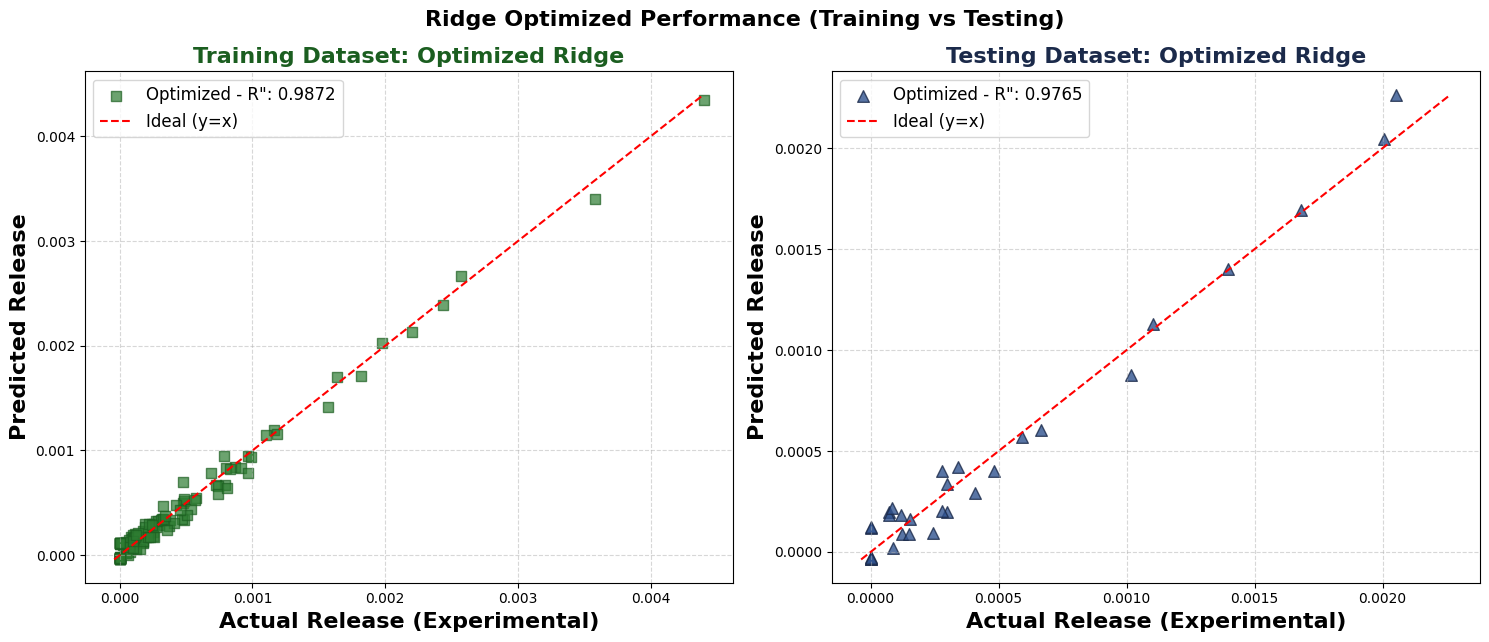

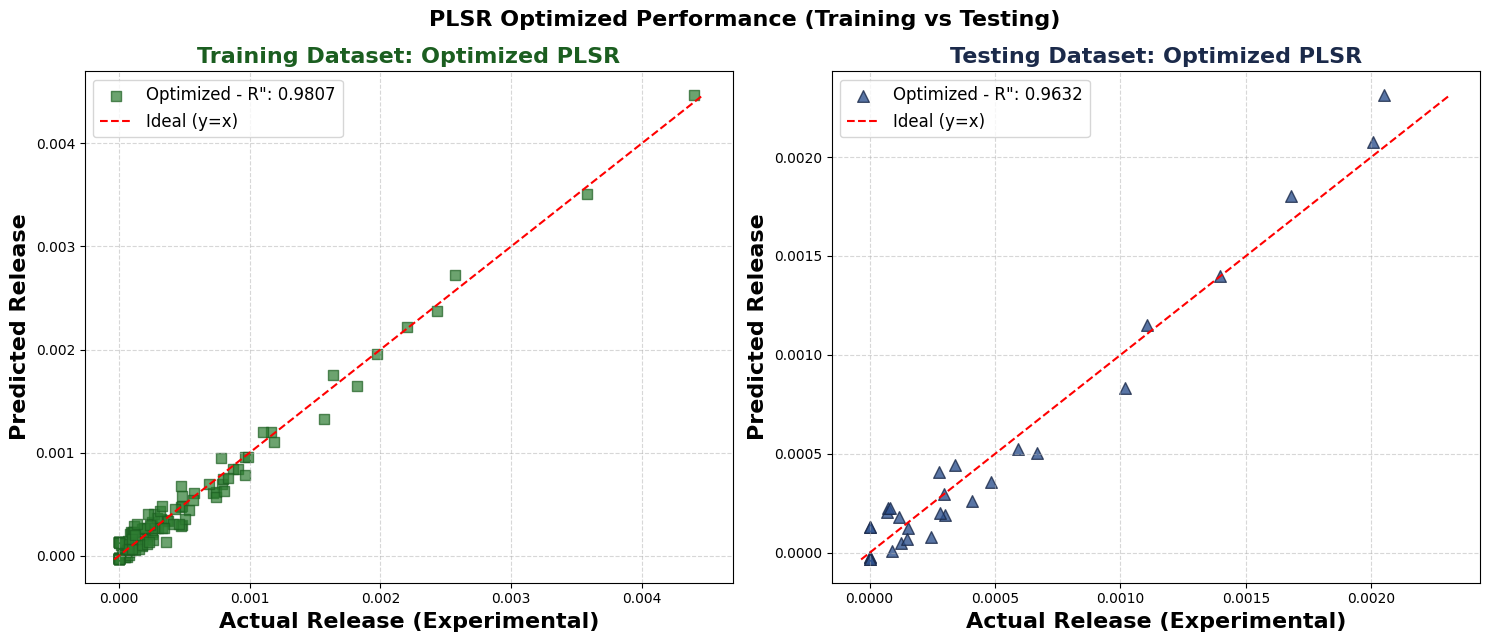

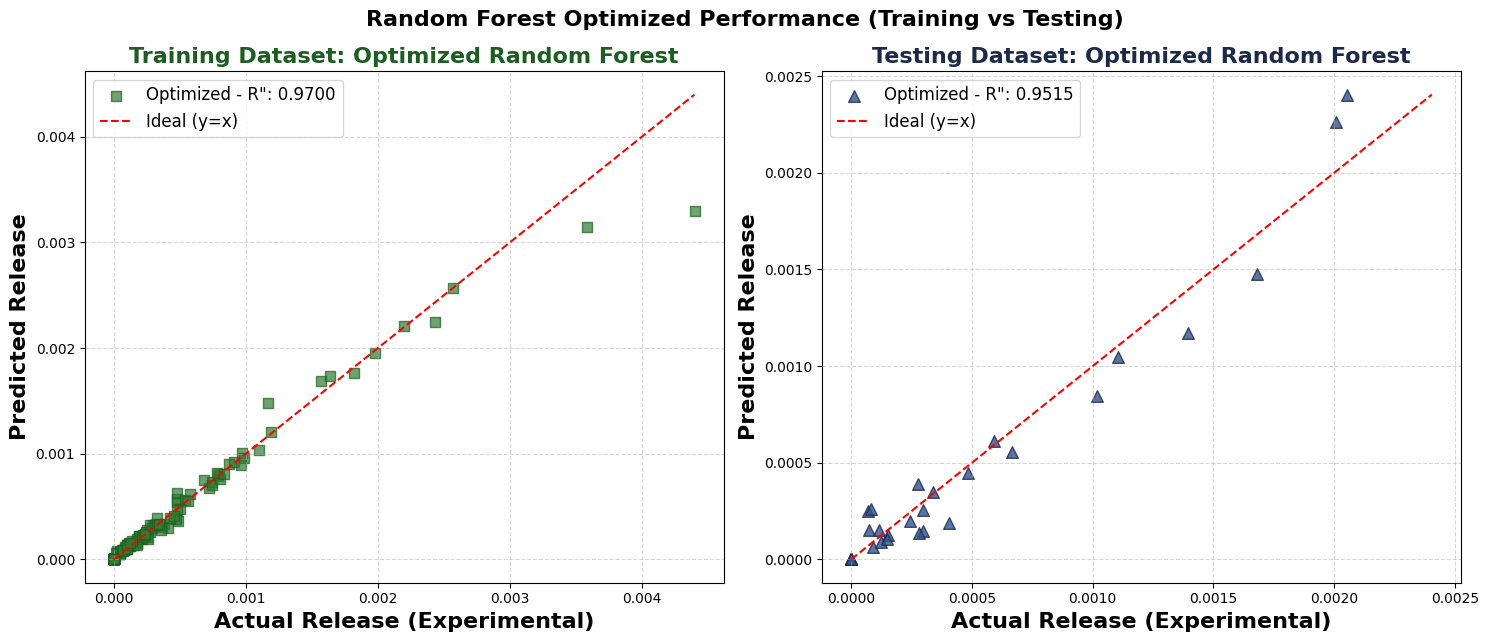

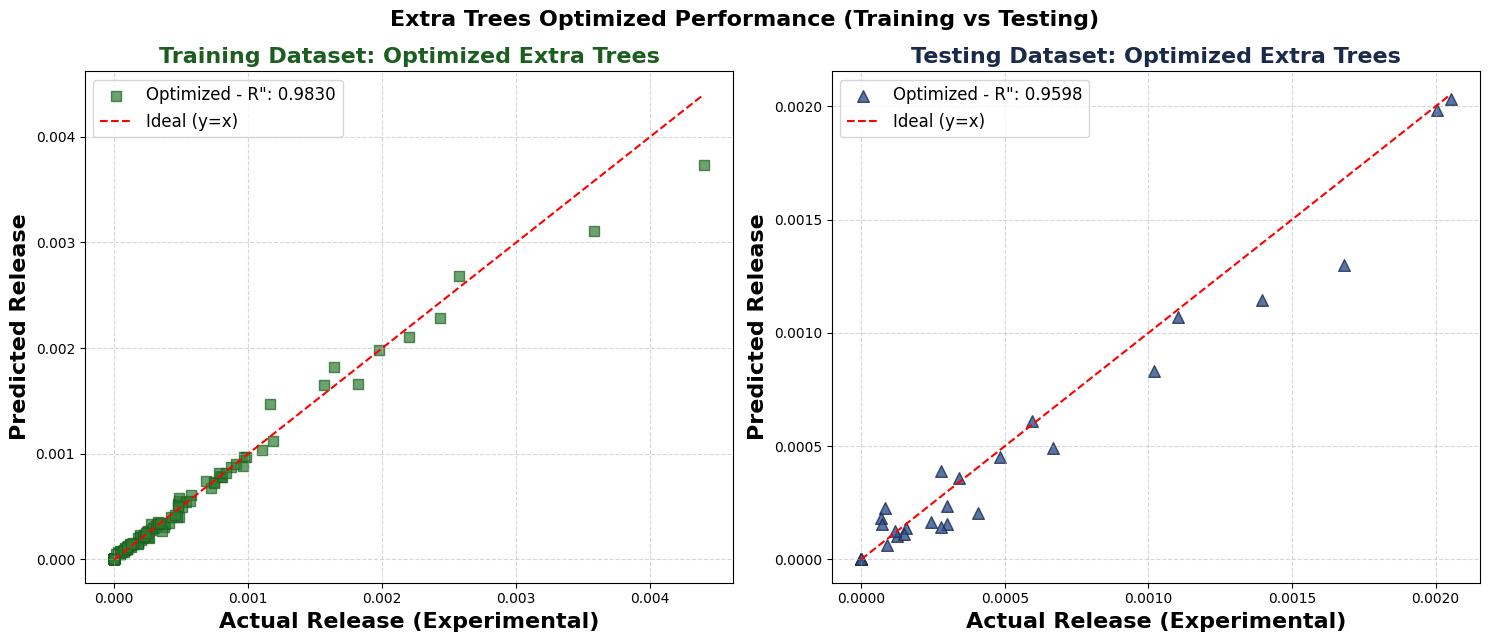

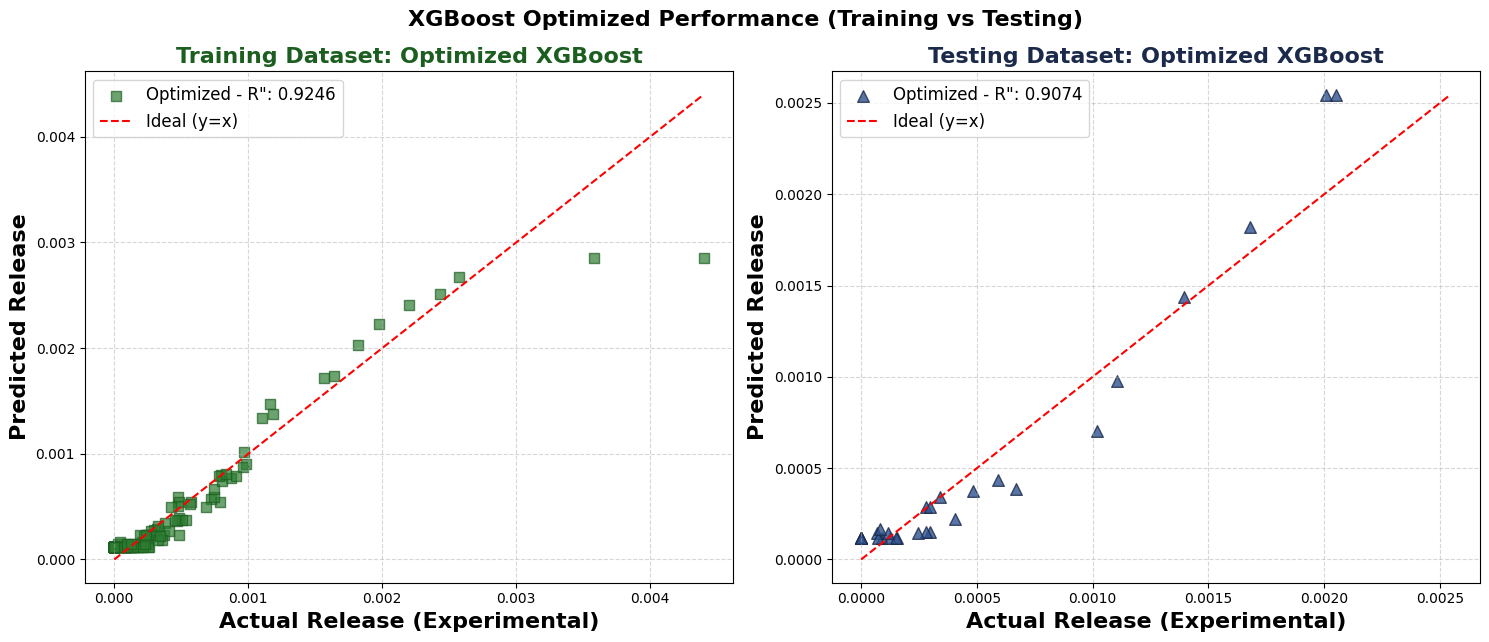

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import joblib
import os
from sklearn.metrics import r2_score

# Daftar semua model yang akan divisualisasikan
all_models = ["Ridge", "PLSR", "Random Forest", "Extra Trees", "XGBoost"]

# Map nama model ke file backup pkl jika variabel global tidak ada
model_files = {
    "Ridge": "Release_Final_Ridge.pkl",
    "PLSR": "Release_Final_PLSR.pkl",
    "Random Forest": "Release_Final_RandomForest.pkl",
    "Extra Trees": "Release_Final_ExtraTrees.pkl",
    "XGBoost": "Release_Final_XGBoost.pkl"
}

for model_name in all_models:
    opt_model = None

    # 1. Cek variabel di memori global terlebih dahulu
    if model_name == "Ridge" and 'final_ridge' in globals():
        opt_model = final_ridge
    elif model_name == "PLSR" and 'final_plsr' in globals():
        opt_model = final_plsr
    elif model_name == "Random Forest" and 'final_rf' in globals():
        opt_model = final_rf
    elif model_name == "Extra Trees" and 'final_et' in globals():
        opt_model = final_et
    elif model_name == "XGBoost" and 'final_xgb' in globals():
        opt_model = final_xgb

    # 2. Jika tidak ada di memori, coba load dari file pkl jika filenya ada
    if opt_model is None:
        file_path = model_files[model_name]
        if os.path.exists(file_path):
            opt_model = joblib.load(file_path)
        else:
            print(f"Peringatan: Model '{model_name}' tidak ditemukan di memori maupun di file '{file_path}'. Silakan jalankan sel optimasi model ini terlebih dahulu.")
            continue

    pred_train_opt = opt_model.predict(X_train_processed).ravel()
    pred_test_opt = opt_model.predict(X_test_processed).ravel()

    # 3. Hitung skor R² untuk model yang telah dioptimasi
    r2_train_opt = r2_score(y_train, pred_train_opt)
    r2_test_opt = r2_score(y_test, pred_test_opt)

    # 4. Membuat subplot terpisah untuk Training dan Testing (Hanya Optimized)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

    # --- SUBPLOT 1: TRAINING DATASET (Optimized - Nuansa Hijau) ---
    axes[0].scatter(y_train, pred_train_opt, color='#2e7d32', alpha=0.7, marker='s', s=60, edgecolors='#1b5e20',
                    label=f'Optimized - R": {r2_train_opt:.4f}')

    min_train = min(np.min(y_train), np.min(pred_train_opt))
    max_train = max(np.max(y_train), np.max(pred_train_opt))
    axes[0].plot([min_train, max_train], [min_train, max_train], 'r--', lw=1.5, label='Ideal (y=x)')
    axes[0].set_xlabel('Actual Release (Experimental)', fontsize=16, fontweight='bold')
    axes[0].set_ylabel('Predicted Release', fontsize=16, fontweight='bold')
    axes[0].set_title(f'Training Dataset: Optimized {model_name}', fontsize=16, fontweight='bold', color='#1b5e20')
    axes[0].grid(True, linestyle='--', alpha=0.5)
    axes[0].legend(loc='upper left', fontsize=12)

    # --- SUBPLOT 2: TESTING DATASET (Optimized - Nuansa Biru) ---
    axes[1].scatter(y_test, pred_test_opt, color='#2F528F', alpha=0.8, marker='^', s=70, edgecolors='#1b2a4a',
                    label=f'Optimized - R": {r2_test_opt:.4f}')

    min_test = min(np.min(y_test), np.min(pred_test_opt))
    max_test = max(np.max(y_test), np.max(pred_test_opt))
    axes[1].plot([min_test, max_test], [min_test, max_test], 'r--', lw=1.5, label='Ideal (y=x)')
    axes[1].set_xlabel('Actual Release (Experimental)', fontsize=16, fontweight='bold')
    axes[1].set_ylabel('Predicted Release', fontsize=16, fontweight='bold')
    axes[1].set_title(f'Testing Dataset: Optimized {model_name}', fontsize=16, fontweight='bold', color='#1b2a4a')
    axes[1].grid(True, linestyle='--', alpha=0.5)
    axes[1].legend(loc='upper left', fontsize=12)

    plt.suptitle(f'{model_name} Optimized Performance (Training vs Testing)', fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()